In [20]:
import os
import scanpy
import scanpy as sc
import numpy as np
import pandas as pd

import random

random.seed(10)

In [21]:
# Directory h5ad data (Just test for a specific sample)
#os.chdir("/data/ciperi/Atlas_SSC/LUNG/GSE212109")
#directory_h5ad = "GSE212109.h5ad"
#adata_merged = scanpy.read_h5ad(directory_h5ad)

#print(adata_merged)

In [22]:
#print(adata_merged.raw.X)

In [23]:
import scanpy as sc
from pathlib import Path

# Base directory containing all GSE folders / h5ad files
base_dir = Path("/home/ciperi/data/Atlas_SSC/SYNOVIUM")

# Find all .h5ad files inside directories starting with GSE
h5ad_files = sorted(base_dir.glob("GSE*/**/*.h5ad"))
print(h5ad_files)

print(f"Found {len(h5ad_files)} .h5ad files:")
for f in h5ad_files:
    print("  -", f)

# Read each dataset
adatas = []
for f in h5ad_files:
    print(f"\nReading {f.name} ...")
    adata = sc.read_h5ad(f)

    # Add a metadata column with the dataset name
    adata.obs["dataset"] = f.parent.name

    # Optionally make variable names unique
    adata.var_names_make_unique()

    adatas.append(adata)

# 🧬 --- Gene overlap comparison before merging ---
gene_lists = [set(a.var_names) for a in adatas]
shared_genes = set.intersection(*gene_lists)
all_genes = set.union(*gene_lists)

print("\n🧬 Gene overlap summary:")
print(f" - Total unique genes across all datasets: {len(all_genes):,}")
print(f" - Shared genes across all datasets: {len(shared_genes):,}")
print(f" - Percentage shared: {len(shared_genes)/len(all_genes)*100:.2f}%")

# Optional: show how many genes are shared per dataset
for i, a in enumerate(adatas):
    perc = len(shared_genes & set(a.var_names)) / len(a.var_names) * 100
    print(f"   {a.obs['dataset'][0]}: {perc:.2f}% shared genes")
    

# Merge all datasets
print("\nMerging all datasets ...")
adata_merged = adatas[0].concatenate(
    adatas[1:],
    batch_key="batch",
    batch_categories=[a.obs["dataset"][0] for a in adatas]
) #inner join by default (only the common one saved)

# Save merged dataset
output_file = base_dir / "merged_Atlas_SSC.h5ad"
#adata_merged.write(output_file)

print(f"\n✅ Merged AnnData object saved to:\n{output_file}")
print(adata_merged)


[PosixPath('/home/ciperi/data/Atlas_SSC/SYNOVIUM/GSE00000/GSE00000.h5ad')]
Found 1 .h5ad files:
  - /home/ciperi/data/Atlas_SSC/SYNOVIUM/GSE00000/GSE00000.h5ad

Reading GSE00000.h5ad ...

🧬 Gene overlap summary:
 - Total unique genes across all datasets: 36,601
 - Shared genes across all datasets: 36,601
 - Percentage shared: 100.00%
   GSE00000: 100.00% shared genes

Merging all datasets ...


/tmp/ipykernel_3979348/1847496511.py:42: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"   {a.obs['dataset'][0]}: {perc:.2f}% shared genes")
/tmp/ipykernel_3979348/1847496511.py:50: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  batch_categories=[a.obs["dataset"][0] for a in adatas]
/tmp/ipykernel_3979348/1847496511.py:47: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata_merged = adatas[0].concatenate(



✅ Merged AnnData object saved to:
/home/ciperi/data/Atlas_SSC/SYNOVIUM/merged_Atlas_SSC.h5ad
AnnData object with n_obs × n_vars = 62614 × 36601
    obs: 'n_genes', 'sample', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'orig.ident', 'SampleName', 'DiseaseYears', 'Disease', 'DiseaseName', 'Pathotype', 'Sex', 'Sex2', 'Age', 'Localisation', 'Joint', 'Center', 'BiopsyDate', 'Krenn', 'CD15', 'Vascularisation', 'Lymphoidfollicle', 'Granulomas', 'Fibrosis', 'GCTreatment', 'Therapy', 'DMARDTreatment', 'NOpreviousTreatments', 'Autoantibodies', 'Seropositivity', 'RF', 'anti-CCP', 'HLAB27', 'USB', 'USPD', 'CRP', 'D2T', 'NOJoints', 'INVlargeJoints', 'SystemicManifestations', 'Smoking', 'BMI', 'BMIcat', 'BMIcat2', 'Radiograph', 'AxialInvolvement', 'dataset'


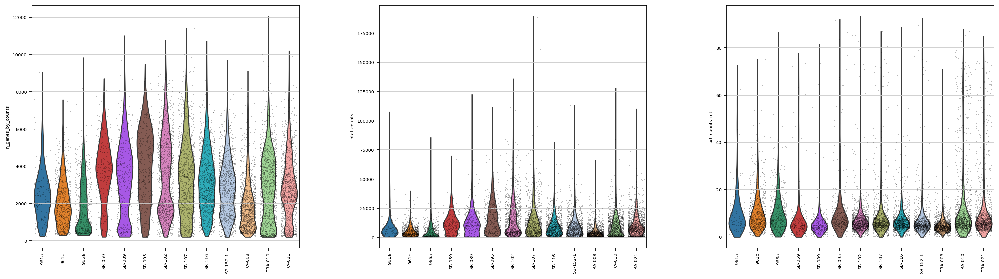

In [24]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 6)

sc.pl.violin(adata_merged,
    ["n_genes_by_counts","total_counts", "pct_counts_mt"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)

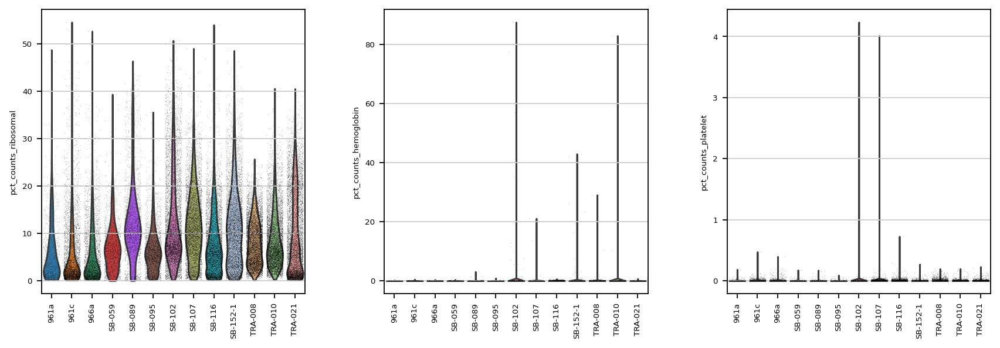

In [25]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 6)
sc.set_figure_params(scanpy=True, fontsize=6)

sc.pl.violin(adata_merged,
    ["pct_counts_ribosomal", "pct_counts_hemoglobin","pct_counts_platelet"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=False,
    size = 0.2 )  # 3 inches per row)  # width x height in inches)

In [26]:
adata_merged.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,NOJoints,INVlargeJoints,SystemicManifestations,Smoking,BMI,BMIcat,BMIcat2,Radiograph,AxialInvolvement,dataset
cell,,,,,,,,,,,,,,,,,,,,,
SB-089_AAACCCACACGCCACA-1-GSE00000,442,SB-089,529.0,442,2.835539,13.232514,0.000000,0.000000,1.196833,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000
SB-089_AAACCCACACTTCCTG-1-GSE00000,577,SB-089,944.0,577,0.635593,0.953390,0.000000,0.000000,1.636049,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000
SB-089_AAACCCAGTGCAGTGA-1-GSE00000,2256,SB-089,4201.0,2256,1.999524,2.642228,0.023804,0.000000,1.862145,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000
SB-089_AAACGAAGTCGCTCGA-1-GSE00000,5019,SB-089,23404.0,5019,8.827551,4.935054,0.000000,0.000000,4.663080,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000
SB-089_AAACGCTAGGAGATAG-1-GSE00000,2371,SB-089,5903.0,2371,9.283415,14.399458,0.000000,0.000000,2.489667,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SB-095_TTTGGTTGTCGTGATT-1-GSE00000,5180,SB-095,20068.0,5180,8.217062,17.002192,0.004983,0.014949,3.874131,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000
SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,6922,SB-095,45053.0,6922,6.740949,7.613256,0.002220,0.000000,6.508668,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000
SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,4866,SB-095,20985.0,4866,5.127472,7.719800,0.009531,0.000000,4.312577,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000


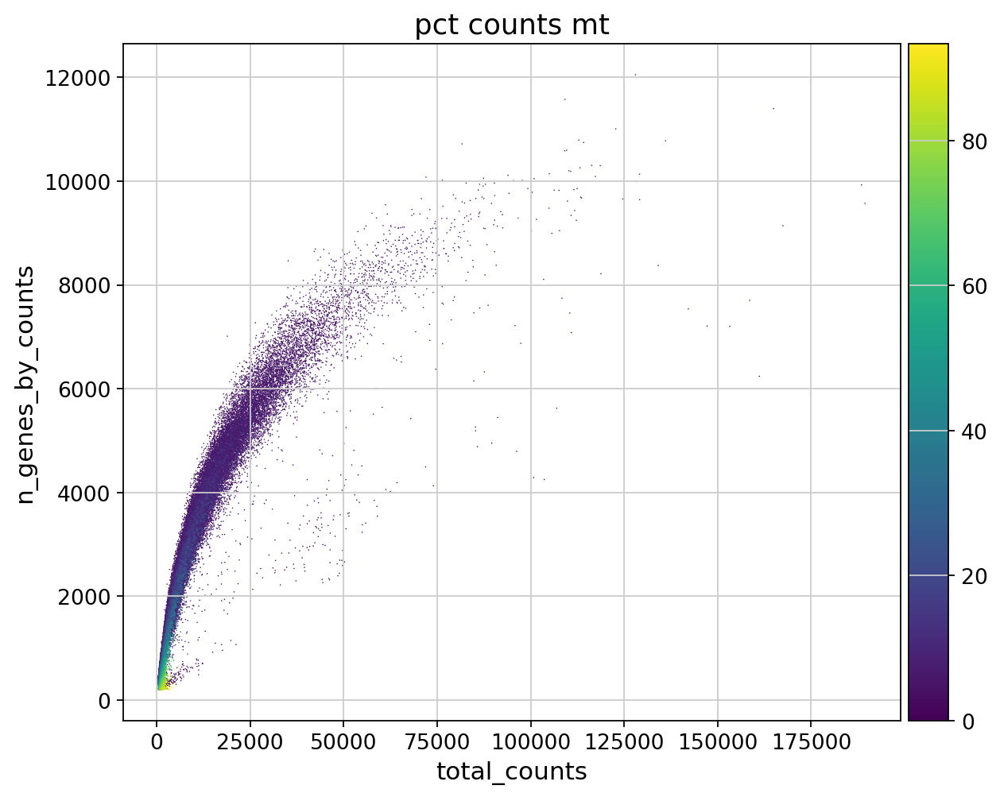

In [27]:
plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.titlesize"] = 16       # Title size
plt.rcParams["axes.labelsize"] = 14       # X and Y label size
plt.rcParams["xtick.labelsize"] = 12      # X tick size
plt.rcParams["ytick.labelsize"] = 12      # Y tick size
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

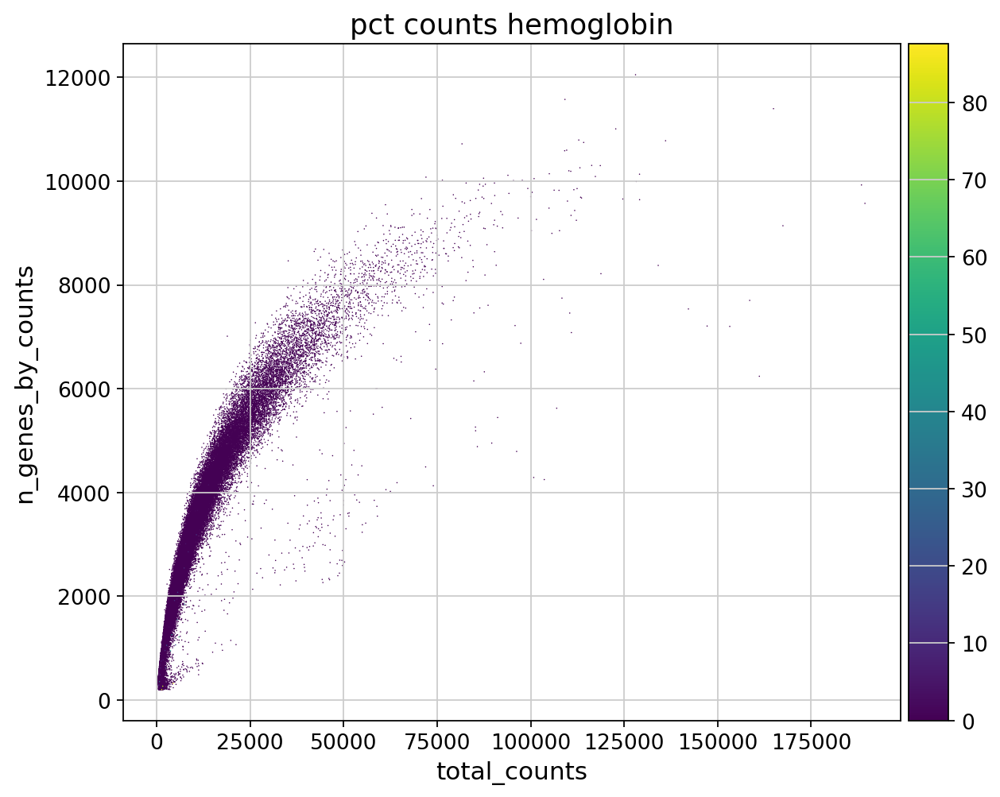

In [28]:
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_hemoglobin")

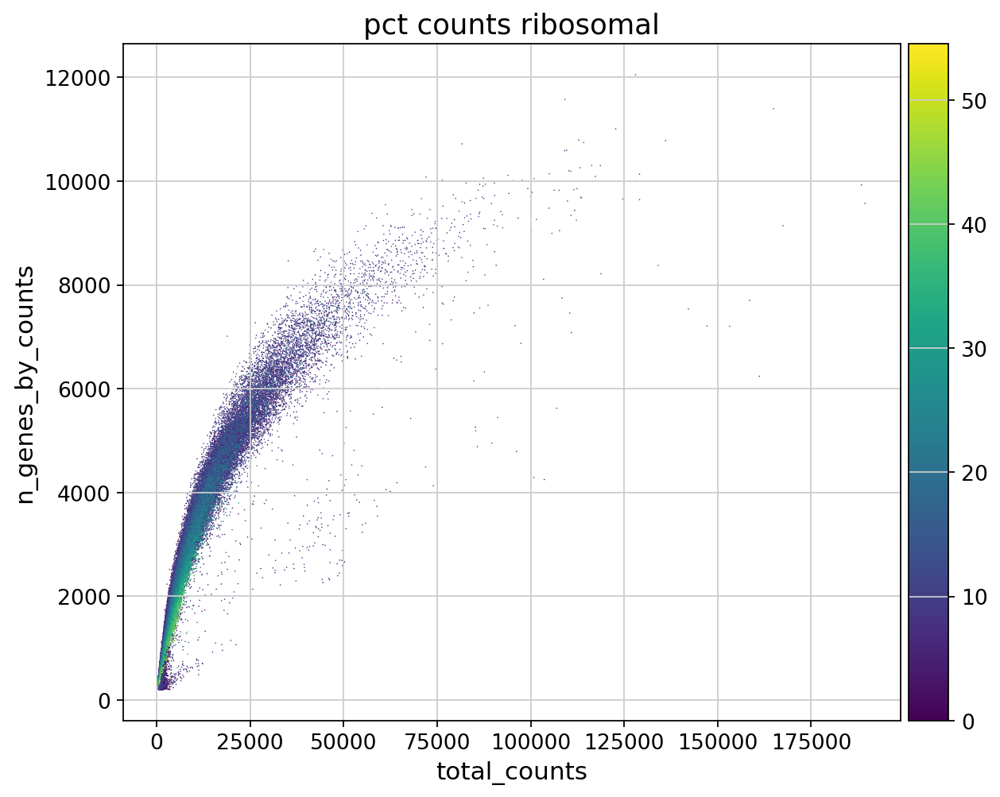

In [29]:
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_ribosomal")

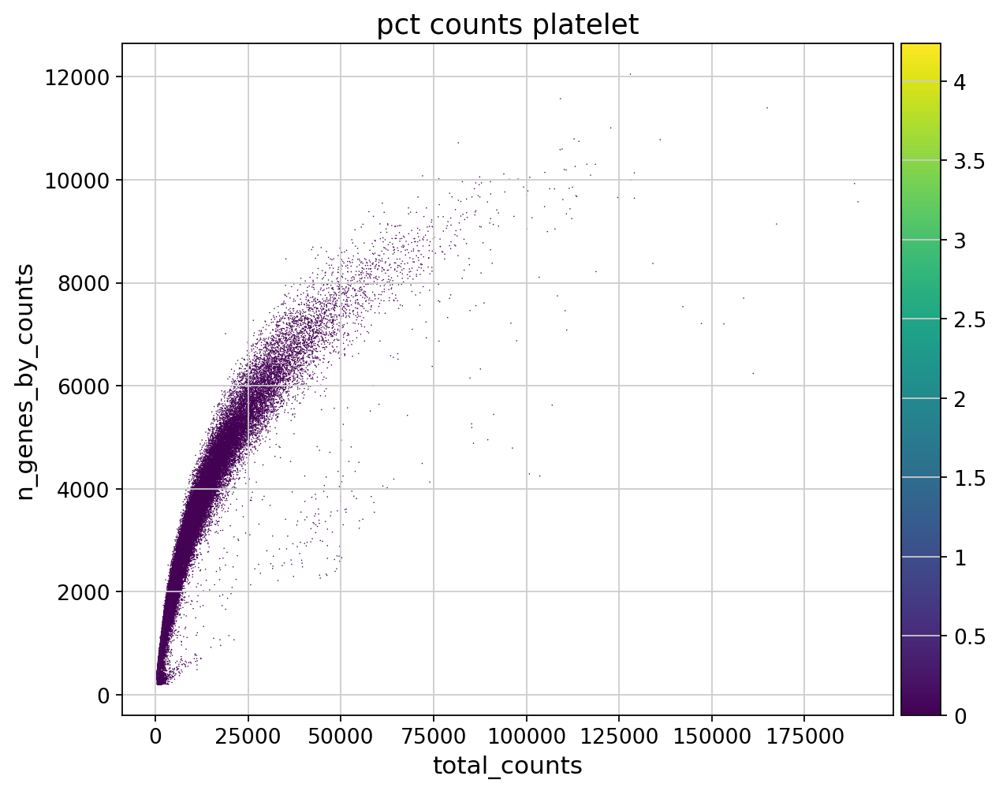

In [30]:
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_platelet")

In [31]:
print(len(adata_merged.obs))

62614


# FILTERING THRESHOLD EXPLORATION

In [32]:
# Define thresholds for filtering
ribo_thresholds_down = np.arange(0, 15, 2.5)  # Ribosomal % from 0% to 15%
ribo_thresholds_up = np.arange(20, 50, 5)  # Ribosomal % from 20% to 60%
# Create a table to store results
results = []

print("Initial number of cells")
print(len(adata_merged.obs))

Initial number of cells
62614


In [33]:
for ribo_down in ribo_thresholds_down:
    for ribo_up in ribo_thresholds_up:
        num_cells_removed = ((adata_merged.obs["pct_counts_ribosomal"] > ribo_down) & 
                             (adata_merged.obs["pct_counts_ribosomal"] < ribo_up)).sum()
        results.append([ribo_down, ribo_up, num_cells_removed])

# Convert to DataFrame
qc_table = pd.DataFrame(results, columns=["Ribo_Threshold down > (%)", "Ribo_Threshold up < (%)", "Cells_Filtered"])
print(qc_table)

    Ribo_Threshold down > (%)  Ribo_Threshold up < (%)  Cells_Filtered
0                         0.0                       20           57011
1                         0.0                       25           60020
2                         0.0                       30           61453
3                         0.0                       35           62138
4                         0.0                       40           62465
5                         0.0                       45           62574
6                         2.5                       20           45789
7                         2.5                       25           48798
8                         2.5                       30           50231
9                         2.5                       35           50916
10                        2.5                       40           51243
11                        2.5                       45           51352
12                        5.0                       20           35958
13    

In [34]:
# Define thresholds for filtering
gene_thresholds = np.arange(5000, 9000, 1000)  # Gene Threshold
count_thresholds = np.arange(30000, 70000, 10000)  # Count Threshold
# Create a table to store results
results = []

print("Initial number of cells")
print(len(adata_merged.obs))

Initial number of cells
62614


In [35]:
for gene in gene_thresholds:
    for count in count_thresholds:
        num_cells_removed = ((adata.obs["total_counts"] < gene) & 
                             (adata.obs["n_genes_by_counts"] < count)).sum()
        results.append([gene, count, num_cells_removed])

# Convert to DataFrame
qc_table = pd.DataFrame(results, columns=["Gene number < (%)", "Reads/UMI counts < (%)", "Cells_Filtered"])
print(qc_table)

    Gene number < (%)  Reads/UMI counts < (%)  Cells_Filtered
0                5000                   30000           24656
1                5000                   40000           24656
2                5000                   50000           24656
3                5000                   60000           24656
4                6000                   30000           28367
5                6000                   40000           28367
6                6000                   50000           28367
7                6000                   60000           28367
8                7000                   30000           31506
9                7000                   40000           31506
10               7000                   50000           31506
11               7000                   60000           31506
12               8000                   30000           34516
13               8000                   40000           34516
14               8000                   50000           34516
15      

In [36]:
# Define thresholds for filtering
mito_thresholds = np.arange(5, 25, 5)  # Ribosomal % from 2.5% to 15%
hemo_thresholds = np.arange(0.5, 2.0, 0.5)  # Hemoglobin % from 0.25% to 1.5%
plat_thresholds = np.arange(0.5, 2.0, 0.5)  # Platelets % from 0.25% to 1.5%
# Create a table to store results
results = []

print("Initial number of cells")
print(len(adata_merged.obs))

Initial number of cells
62614


In [37]:
for mito in mito_thresholds:
    for hemo in hemo_thresholds:
        for plat in plat_thresholds:
            num_cells_removed = ((adata_merged.obs["pct_counts_mt"] < mito) & 
                                 (adata_merged.obs["pct_counts_hemoglobin"] < hemo) &
                                 (adata_merged.obs["pct_counts_platelet"] < plat)).sum()
            results.append([mito, hemo, plat, num_cells_removed])

# Convert to DataFrame
qc_table = pd.DataFrame(results, columns=["Mito_Thr < (%)", "Hemo_Thr < (%)", "Plat_Thr < (%)", "Cells_Filtered"])
print(qc_table)

    Mito_Thr < (%)  Hemo_Thr < (%)  Plat_Thr < (%)  Cells_Filtered
0                5             0.5             0.5           23946
1                5             0.5             1.0           23947
2                5             0.5             1.5           23947
3                5             1.0             0.5           23958
4                5             1.0             1.0           23959
5                5             1.0             1.5           23959
6                5             1.5             0.5           23959
7                5             1.5             1.0           23960
8                5             1.5             1.5           23960
9               10             0.5             0.5           49329
10              10             0.5             1.0           49330
11              10             0.5             1.5           49330
12              10             1.0             0.5           49349
13              10             1.0             1.0           4

# FILTERING STEP (Harmonized with Celina)
## UMI > 200
## Removal genes with < 10 total reads
## % mitocondrial removal after 95th percentile, il less than 20%, 20% filtering by default
## % Gene number and UMI removal after the 99th percentile

In [38]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 6)
sc.set_figure_params(scanpy=True, fontsize=6)

print("Prefilter number of cells")
print(len(adata_merged.obs))

Prefilter number of cells
62614


In [39]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

def adaptive_gene_filter(
    adata,
    feature: str = "total_counts",
    low_base: float = 200,
    plot_hist: bool = True,
    plot_violin: bool = True,
    violin_max_cells: int = 20000
):
    """
    Fixed filtering based on number of genes per cell (n_genes_by_counts).
    Removes cells with too few detected genes, using percentile and dynamic thresholds.
    Keeps same plotting/violin logic as adaptive_ribo_filter().
    """

    values = adata.obs[feature].dropna()

    # --- Manual modification to apply a fixed threshold ---
    low_cutoff = 200
    # --- Apply filtering ---
    mask = adata.obs[feature] >= low_cutoff
    adata_filtered = adata[mask].copy()
    adata_removed = adata[~mask].copy()

    print(f"  • Cells kept: {adata_filtered.n_obs}")
    print(f"  • Cells removed: {adata_removed.n_obs}")

    # --- Histogram ---
    if plot_hist:
        plt.figure(figsize=(6,4))
        plt.hist(values, bins=60, alpha=0.5, label='All cells')
        plt.axvline(low_cutoff, color='b', linestyle='--', label='Low cutoff')
        plt.xlabel(feature)
        plt.ylabel("Cell count")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # --- Memory-efficient violin plots (same as ribosomal filter) ---
    if plot_violin:
        def _subsample(adata_in):
            if adata_in.n_obs > violin_max_cells:
                idx = np.random.choice(adata_in.n_obs, violin_max_cells, replace=False)
                return adata_in[idx, :].copy()
            return adata_in

        adata_filt_sub = _subsample(adata_filtered)
        adata_rem_sub = _subsample(adata_removed)

        print(f"\nGenerating violin plots (subsampled):")
        print(f"  Filtered: {adata_filt_sub.n_obs} cells, Removed: {adata_rem_sub.n_obs} cells")

        # Filtered cells
        print("\nFiltered cells:")
        sc.pl.violin(
            adata_filt_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_filt_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

        # Removed cells
        print("\nRemoved cells:")
        sc.pl.violin(
            adata_rem_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_rem_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

    return adata_filtered, adata_removed


  • Cells kept: 62614
  • Cells removed: 0


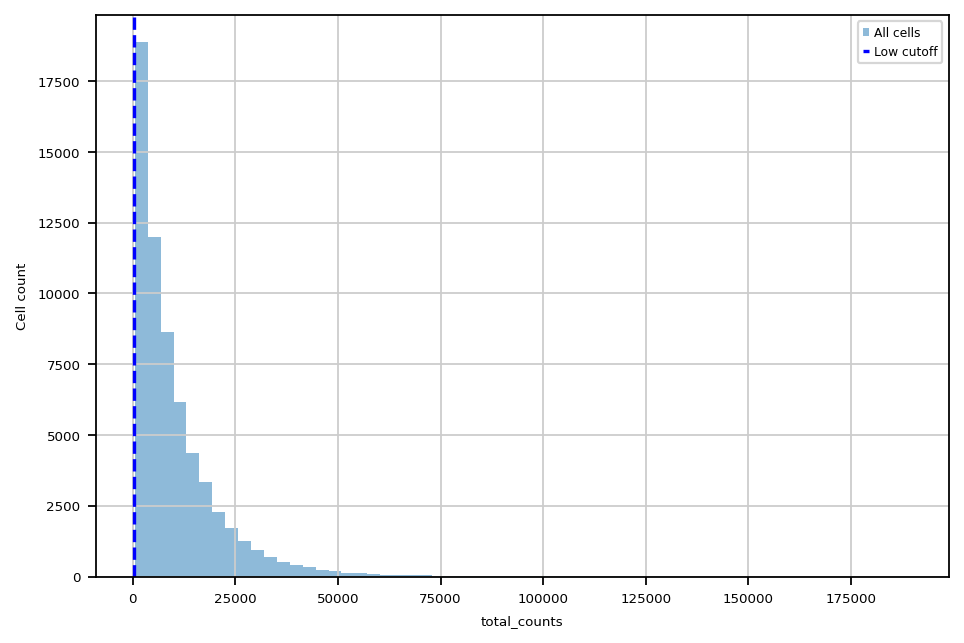


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 0 cells

Filtered cells:


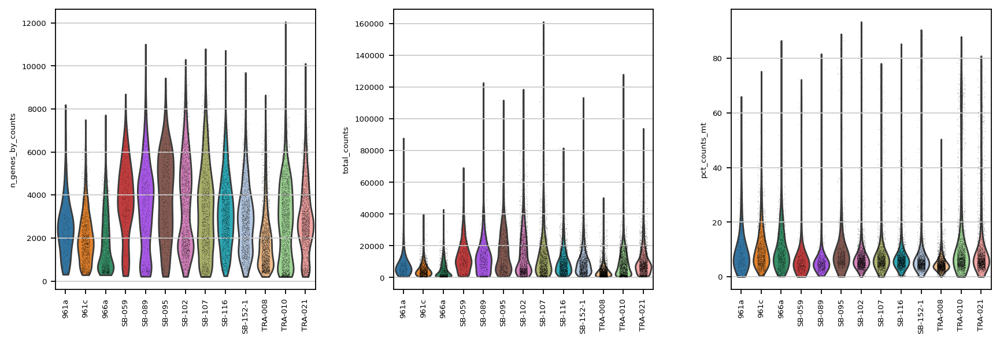

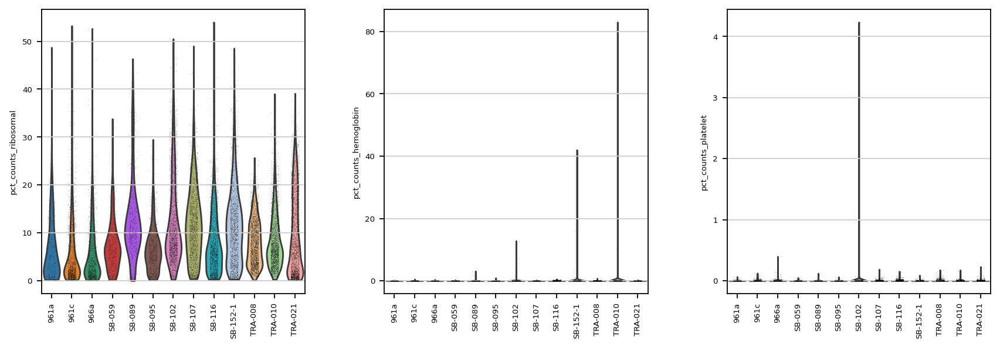


Removed cells:


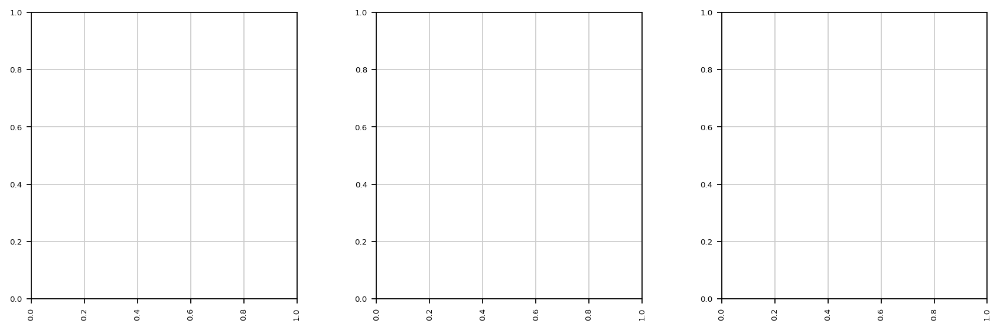

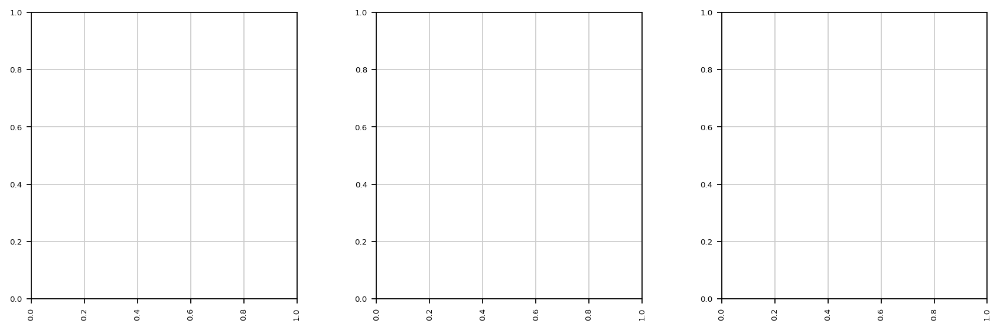

In [40]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="total_counts",
    low_base=200,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)


In [41]:
import scanpy as sc
import numpy as np

print(f"Genes before: {adata_merged.n_vars}")

# Calcola il totale delle reads per gene (somma su tutte le cellule)
gene_counts = np.array(adata_merged.X.sum(axis=0)).flatten()

# Crea una maschera booleana: True per i geni con >= 10 reads
gene_mask = gene_counts >= 10

# Filtra l'AnnData
adata_merged = adata_merged[:, gene_mask].copy()

print(f"Genes after: {adata_merged.n_vars}")

Genes before: 36601
Genes after: 30520


# After Filtering and clustering

In [42]:
adata_merged.raw = adata_merged.copy()
sc.pp.normalize_total(adata_merged, target_sum=1e4)
print(adata_merged.raw.X)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 180369502 stored elements and shape (62614, 30520)>
  Coords	Values
  (0, 6)	1.0
  (0, 109)	1.0
  (0, 172)	1.0
  (0, 198)	1.0
  (0, 367)	1.0
  (0, 514)	1.0
  (0, 533)	1.0
  (0, 592)	1.0
  (0, 935)	1.0
  (0, 938)	1.0
  (0, 942)	1.0
  (0, 992)	1.0
  (0, 994)	1.0
  (0, 1008)	1.0
  (0, 1025)	1.0
  (0, 1144)	1.0
  (0, 1157)	1.0
  (0, 1175)	1.0
  (0, 1261)	2.0
  (0, 1441)	1.0
  (0, 1453)	1.0
  (0, 1525)	1.0
  (0, 1588)	1.0
  (0, 1668)	1.0
  (0, 1733)	1.0
  :	:
  (62613, 30441)	1.0
  (62613, 30449)	1.0
  (62613, 30450)	1.0
  (62613, 30454)	1.0
  (62613, 30457)	1.0
  (62613, 30462)	1.0
  (62613, 30464)	1.0
  (62613, 30467)	3.0
  (62613, 30478)	2.0
  (62613, 30487)	4.0
  (62613, 30489)	1.0
  (62613, 30494)	79.0
  (62613, 30495)	73.0
  (62613, 30496)	216.0
  (62613, 30497)	198.0
  (62613, 30498)	4.0
  (62613, 30499)	202.0
  (62613, 30500)	218.0
  (62613, 30501)	157.0
  (62613, 30502)	6.0
  (62613, 30503)	137.0
  (62613, 30504)	40.0
  

In [43]:
import re

print(f"Original genes: {adata_merged.n_vars}")

# Keep genes that do NOT match the pattern: ends with .digit
pattern = re.compile(r".*\.\d+$")
keep_genes = [not pattern.match(gene) for gene in adata_merged.var_names]

# Subset the AnnData object
adata2 = adata_merged[:, keep_genes].copy()

print(f"Filtered genes: {adata2.n_vars}")

Original genes: 30520
Filtered genes: 21302


In [44]:
cite_genes = adata.var_names[adata.var_names.str.contains("CITE", case=False, na=False)]
print(cite_genes)

Index(['CITED4', 'CITED2', 'CITED1'], dtype='object')


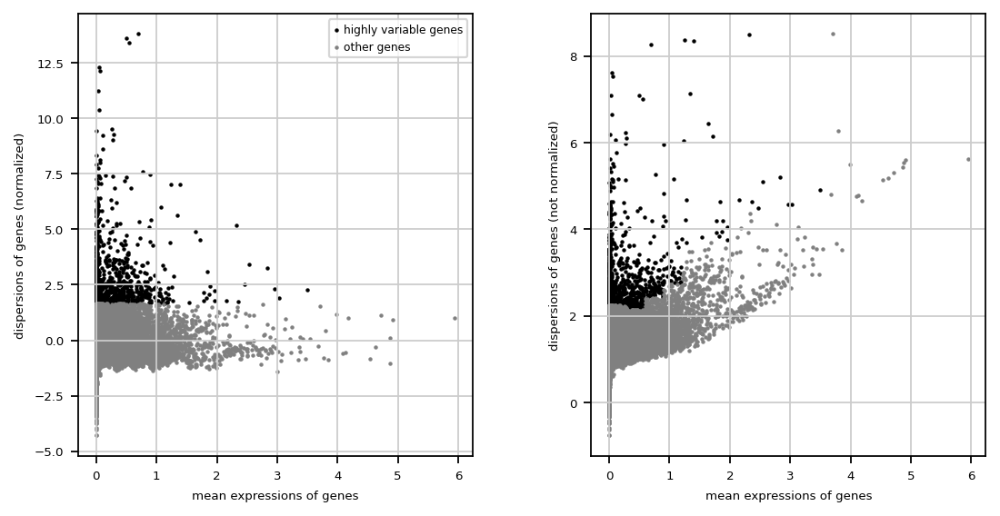

In [45]:
sc.pp.log1p(adata2)
sc.pp.highly_variable_genes(adata2, n_top_genes=1000)
#sc.pp.highly_variable_genes(adata2, min_mean=0.0125, max_mean=3, min_disp=0.5, n_top_genes=1000)
sc.pl.highly_variable_genes(adata2)

In [46]:
hv_genes = adata2.var.highly_variable
print(hv_genes)
adata_hv = adata2[:, hv_genes].copy()

LINC01409    False
FAM87B       False
LINC01128    False
LINC00115    False
FAM41C       False
             ...  
MT-ND4       False
MT-ND5       False
MT-ND6       False
MT-CYB       False
MAFIP        False
Name: highly_variable, Length: 21302, dtype: bool


In [49]:
import numpy as np
import skimage

# Run Scrublet
sc.pp.scrublet(adata_hv, use_approx_neighbors=True, sim_doublet_ratio=1, n_neighbors=10, n_prin_comps=5 )

print("predicted doublets")
print(adata_hv.obs['predicted_doublet'].sum())  # conta i True direttamente

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/legacy_api_wrap/__init__.py:82: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)


predicted doublets
940


cell
SB-089_AAACCCACACGCCACA-1-GSE00000    0.002500
SB-089_AAACCCACACTTCCTG-1-GSE00000    0.005236
SB-089_AAACCCAGTGCAGTGA-1-GSE00000    0.250000
SB-089_AAACGAAGTCGCTCGA-1-GSE00000    0.050000
SB-089_AAACGCTAGGAGATAG-1-GSE00000    0.002500
                                        ...   
SB-095_TTTGGTTGTCGTGATT-1-GSE00000    0.019355
SB-095_TTTGGTTGTGTCCGTG-1-GSE00000    0.019355
SB-095_TTTGTTGAGGCGAAGG-1-GSE00000    0.191489
SB-095_TTTGTTGCATAATGAG-1-GSE00000    0.011561
SB-095_TTTGTTGGTCGGCACT-1-GSE00000    0.059406
Name: doublet_score, Length: 62614, dtype: float64
cell
SB-089_AAACCCACACGCCACA-1-GSE00000    False
SB-089_AAACCCACACTTCCTG-1-GSE00000    False
SB-089_AAACCCAGTGCAGTGA-1-GSE00000     True
SB-089_AAACGAAGTCGCTCGA-1-GSE00000    False
SB-089_AAACGCTAGGAGATAG-1-GSE00000    False
                                      ...  
SB-095_TTTGGTTGTCGTGATT-1-GSE00000    False
SB-095_TTTGGTTGTGTCCGTG-1-GSE00000    False
SB-095_TTTGTTGAGGCGAAGG-1-GSE00000    False
SB-095_TTTGTTGCATAATGAG-1-

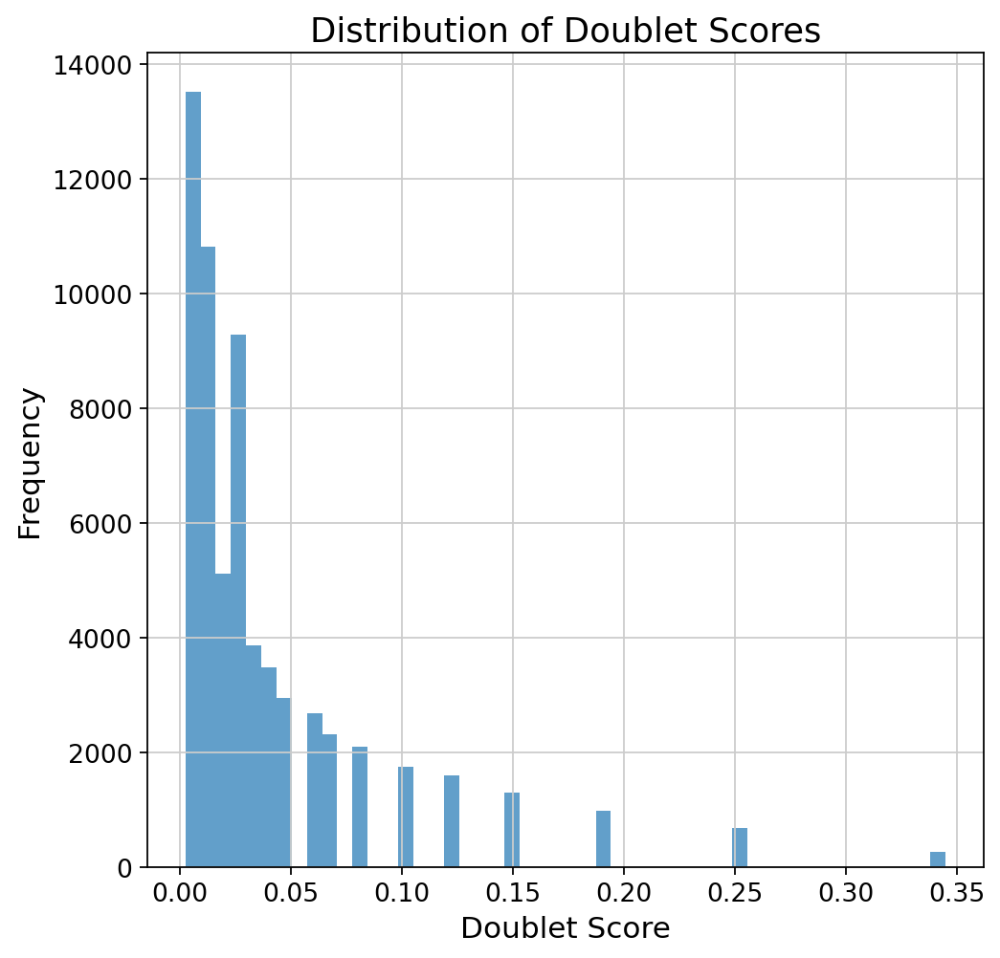

In [50]:
import matplotlib.pyplot as plt


plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.titlesize"] = 16       # Title size
plt.rcParams["axes.labelsize"] = 14       # X and Y label size
plt.rcParams["xtick.labelsize"] = 12      # X tick size
plt.rcParams["ytick.labelsize"] = 12      # Y tick size

# Scrublet results are stored in the AnnData object
# Doublet scores
print(adata_hv.obs['doublet_score'])
# Predicted doublets
print(adata_hv.obs['predicted_doublet'])

# Histogram of doublet scores
adata_hv.obs['doublet_score'].plot.hist(bins=50, alpha=0.7)
plt.xlabel('Doublet Score')
plt.ylabel('Frequency')
plt.title('Distribution of Doublet Scores')
plt.show()

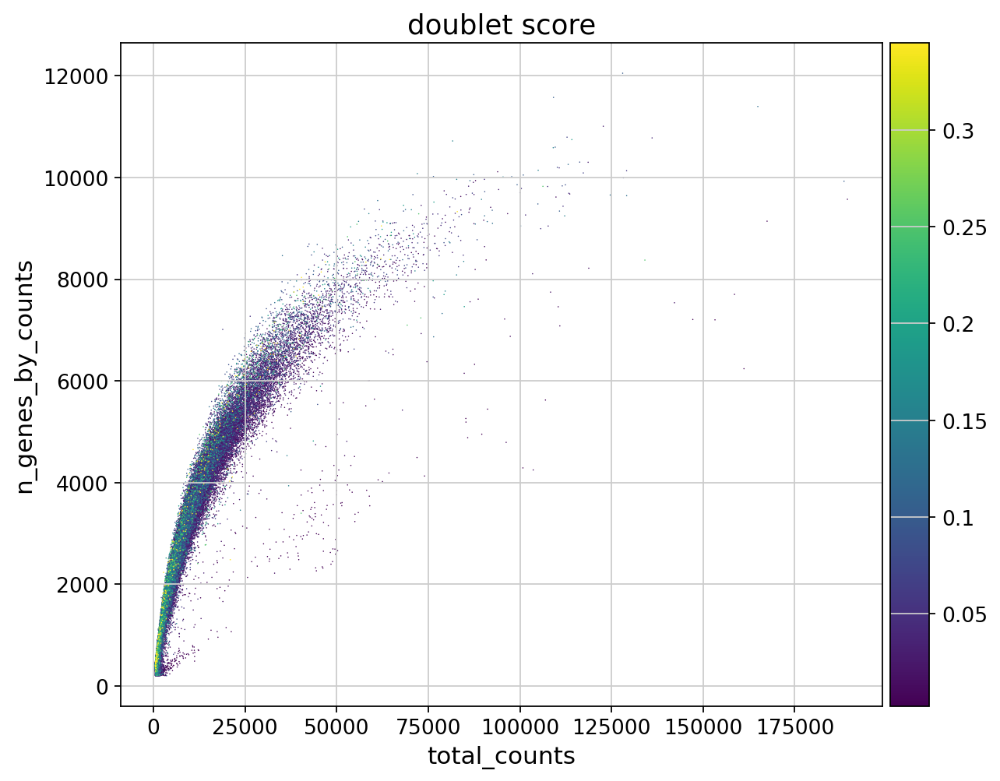

In [51]:
plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.titlesize"] = 16       # Title size
plt.rcParams["axes.labelsize"] = 14       # X and Y label size
plt.rcParams["xtick.labelsize"] = 12      # X tick size
plt.rcParams["ytick.labelsize"] = 12      # Y tick size
sc.pl.scatter(adata_hv, x="total_counts", y="n_genes_by_counts", color="doublet_score")

In [52]:
adata_hv.obs['predicted_doublet'] = adata_hv.obs['predicted_doublet'].fillna(False).astype(int)  # 1 = doublet, 0 = singlet

/tmp/ipykernel_3979348/417454685.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  adata_hv.obs['predicted_doublet'] = adata_hv.obs['predicted_doublet'].fillna(False).astype(int)  # 1 = doublet, 0 = singlet


In [53]:
adata3 = adata2
adata3.obs['predicted_doublet'] = adata_hv.obs['predicted_doublet'].copy()
adata3.obs['doublet_score'] = adata_hv.obs['doublet_score'].copy()

print("Number of cells")
print(len(adata3.obs))

Number of cells
62614


In [54]:
adata_removed = adata3[adata3.obs["predicted_doublet"] == 1].copy()
adata3 = adata3[adata3.obs["predicted_doublet"] == 0].copy()

print("Number of cells post doublets")
print(len(adata3.obs))

Number of cells post doublets
61674


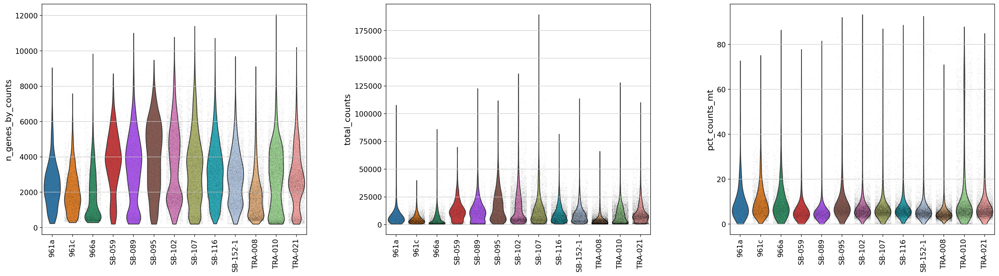

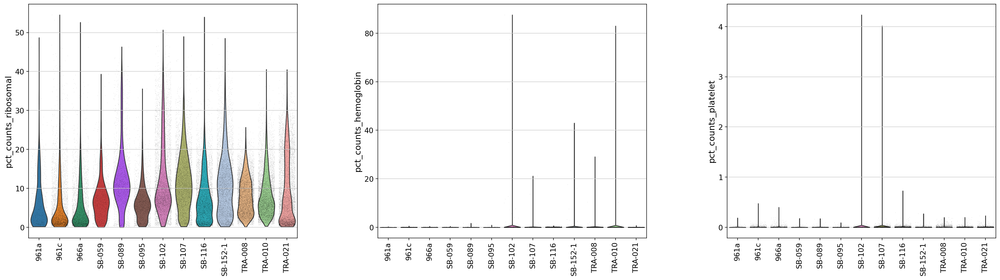

In [55]:
sc.pl.violin(adata3,
    ["n_genes_by_counts", "total_counts","pct_counts_mt"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)
sc.pl.violin(adata3,
    ["pct_counts_ribosomal","pct_counts_hemoglobin","pct_counts_platelet" ],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)

Cells removed
940


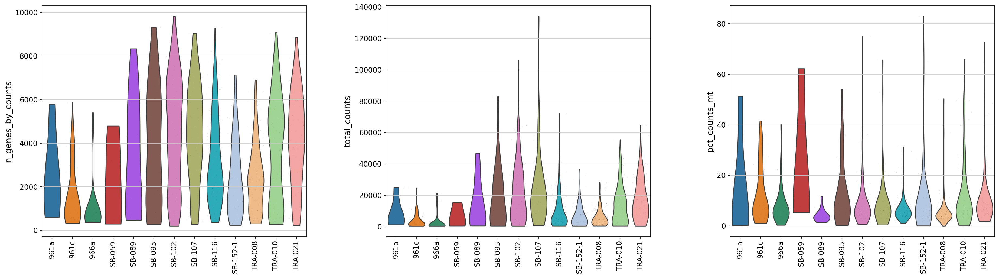

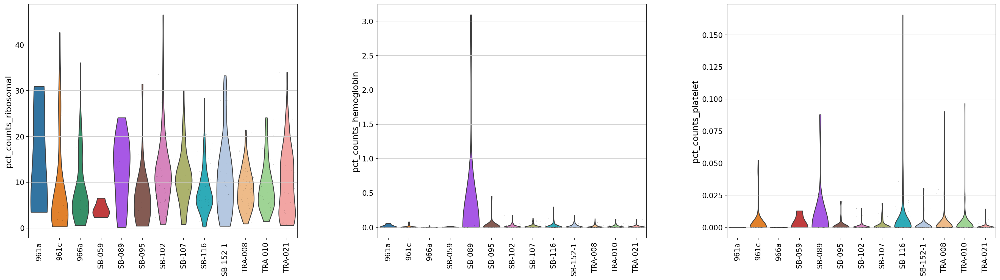

In [56]:
print("Cells removed")
print(len(adata_removed.obs))
sc.pl.violin(adata_removed,
    ["n_genes_by_counts", "total_counts","pct_counts_mt"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)
sc.pl.violin(adata_removed,
    ["pct_counts_ribosomal","pct_counts_hemoglobin","pct_counts_platelet" ],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)

In [57]:
print("Average number of cells per sample")
print(len(adata3.obs)/adata3.obs["sample"].nunique())

Average number of cells per sample
4744.153846153846


In [58]:
adata3.obs["sample"].nunique()

13

In [59]:
## Scale data
#sc.pp.scale(adata3, max_value=10)
## 

sc.tl.pca(adata3, svd_solver="arpack", use_highly_variable=True)

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


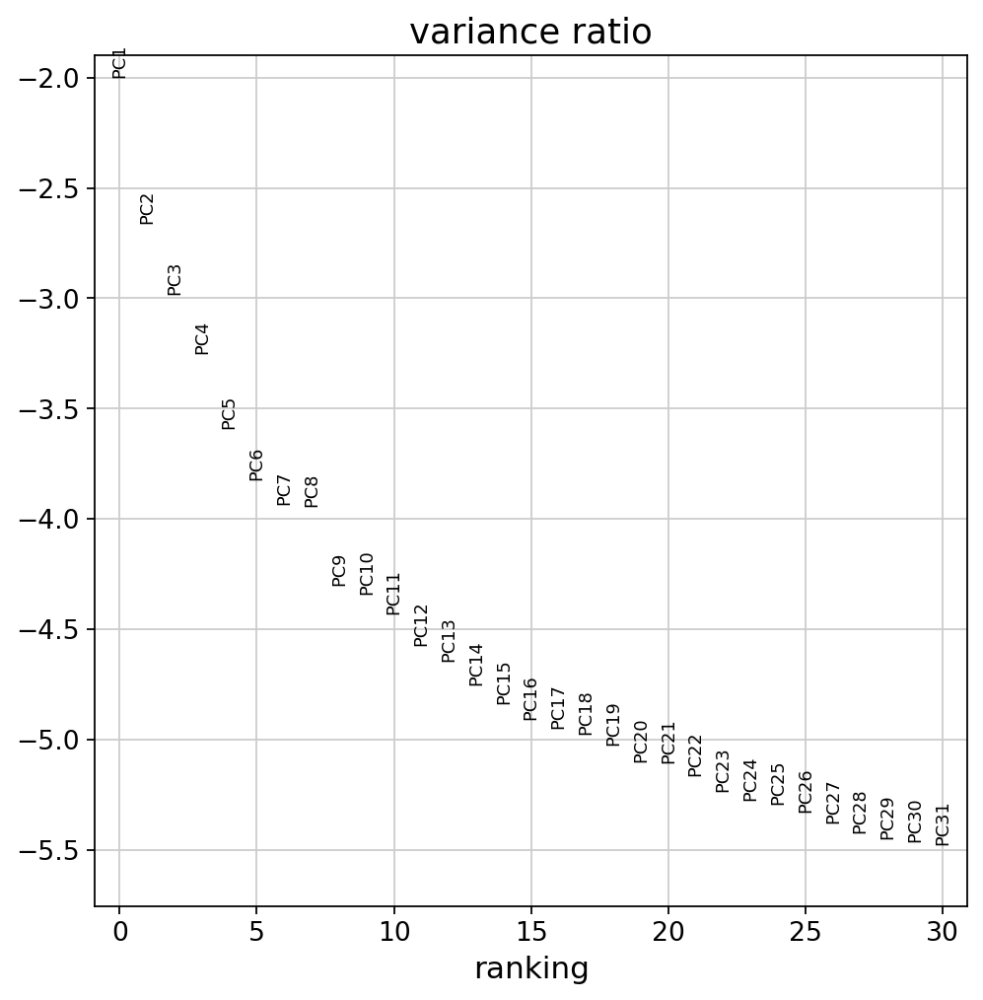

In [60]:
sc.pl.pca_variance_ratio(adata3, log=True)

In [61]:
sc.pp.neighbors(adata3, n_neighbors=15, n_pcs=50)

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [62]:
sc.tl.umap(adata3)

In [63]:
adata3.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,SystemicManifestations,Smoking,BMI,BMIcat,BMIcat2,Radiograph,AxialInvolvement,dataset,predicted_doublet,doublet_score
cell,,,,,,,,,,,,,,,,,,,,,
SB-089_AAACCCACACGCCACA-1-GSE00000,442,SB-089,529.0,442,2.835539,13.232514,0.000000,0.000000,1.196833,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000,0,0.002500
SB-089_AAACCCACACTTCCTG-1-GSE00000,577,SB-089,944.0,577,0.635593,0.953390,0.000000,0.000000,1.636049,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000,0,0.005236
SB-089_AAACGAAGTCGCTCGA-1-GSE00000,5019,SB-089,23404.0,5019,8.827551,4.935054,0.000000,0.000000,4.663080,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000,0,0.050000
SB-089_AAACGCTAGGAGATAG-1-GSE00000,2371,SB-089,5903.0,2371,9.283415,14.399458,0.000000,0.000000,2.489667,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000,0,0.002500
SB-089_AAACGCTGTGGATGAC-1-GSE00000,4413,SB-089,16451.0,4413,6.637894,11.713573,0.000000,0.000000,3.727850,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000,0,0.029197
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SB-095_TTTGGTTGTCGTGATT-1-GSE00000,5180,SB-095,20068.0,5180,8.217062,17.002192,0.004983,0.014949,3.874131,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000,0,0.019355
SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,6922,SB-095,45053.0,6922,6.740949,7.613256,0.002220,0.000000,6.508668,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000,0,0.019355
SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,4866,SB-095,20985.0,4866,5.127472,7.719800,0.009531,0.000000,4.312577,GSE00000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GSE00000,0,0.191489


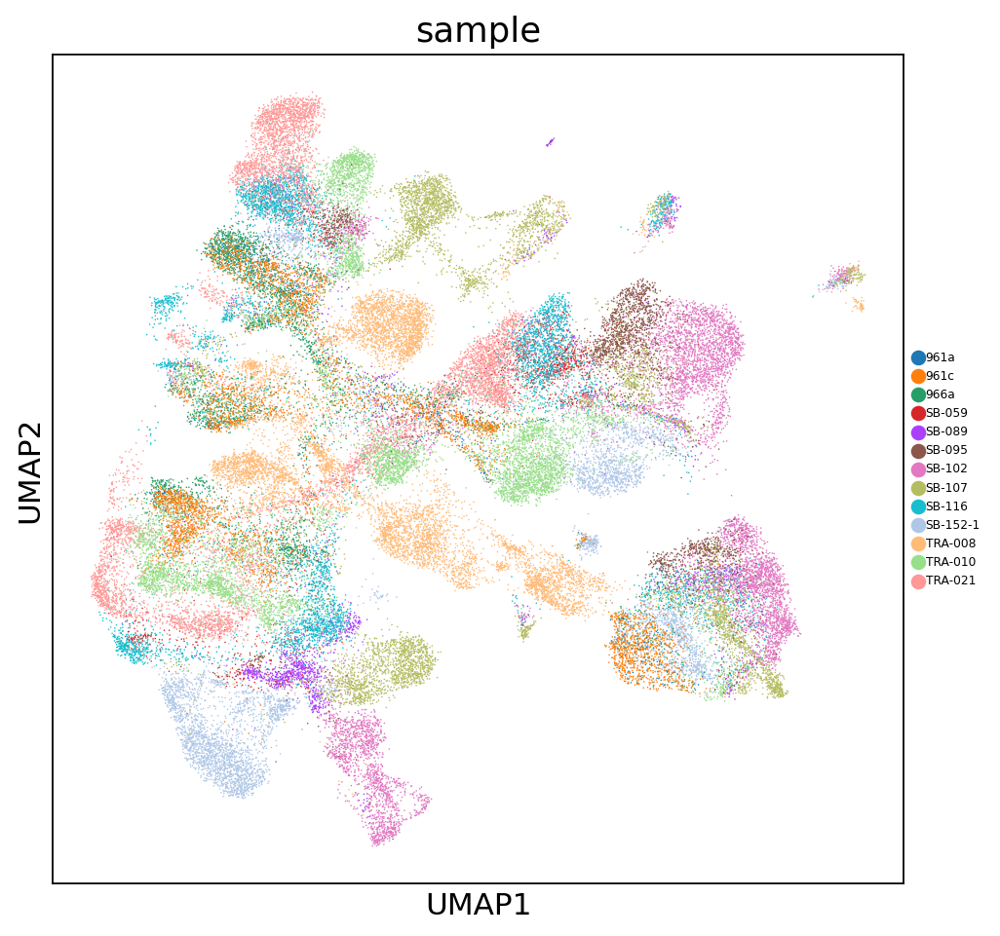

In [64]:
sc.pl.umap(adata3, color=['sample'])

SB-089


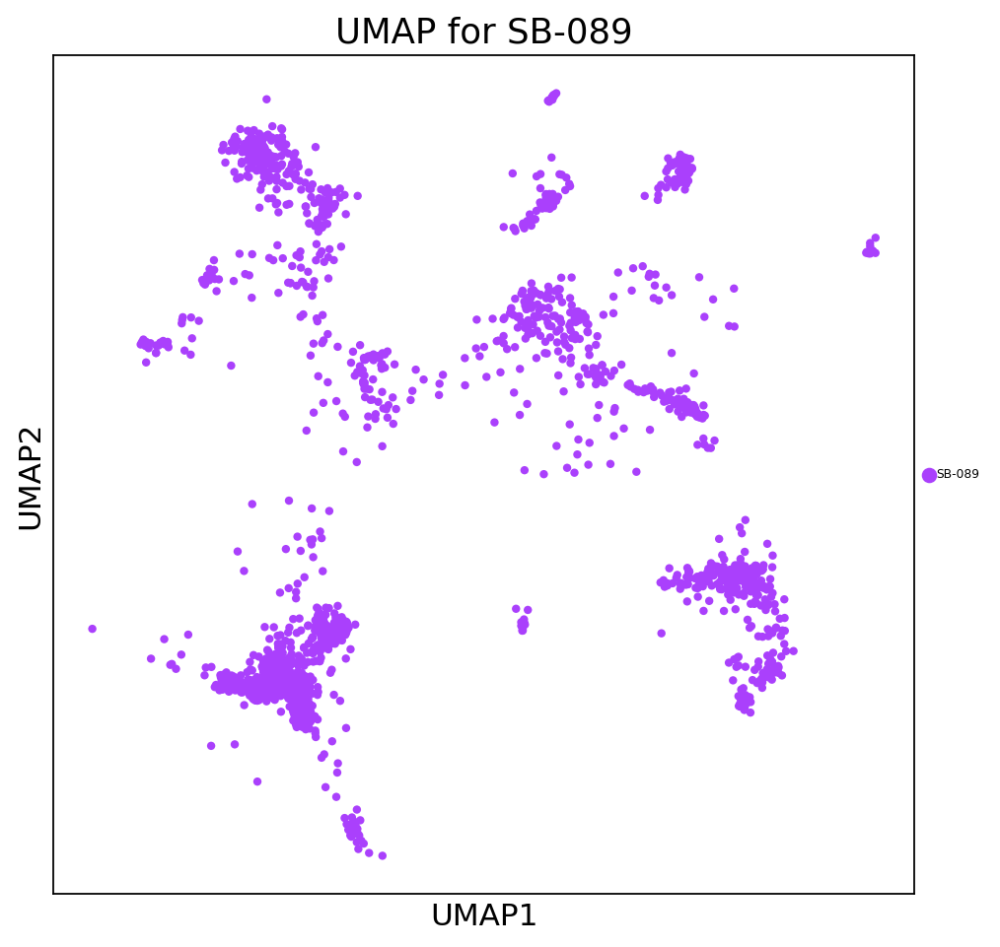

SB-059


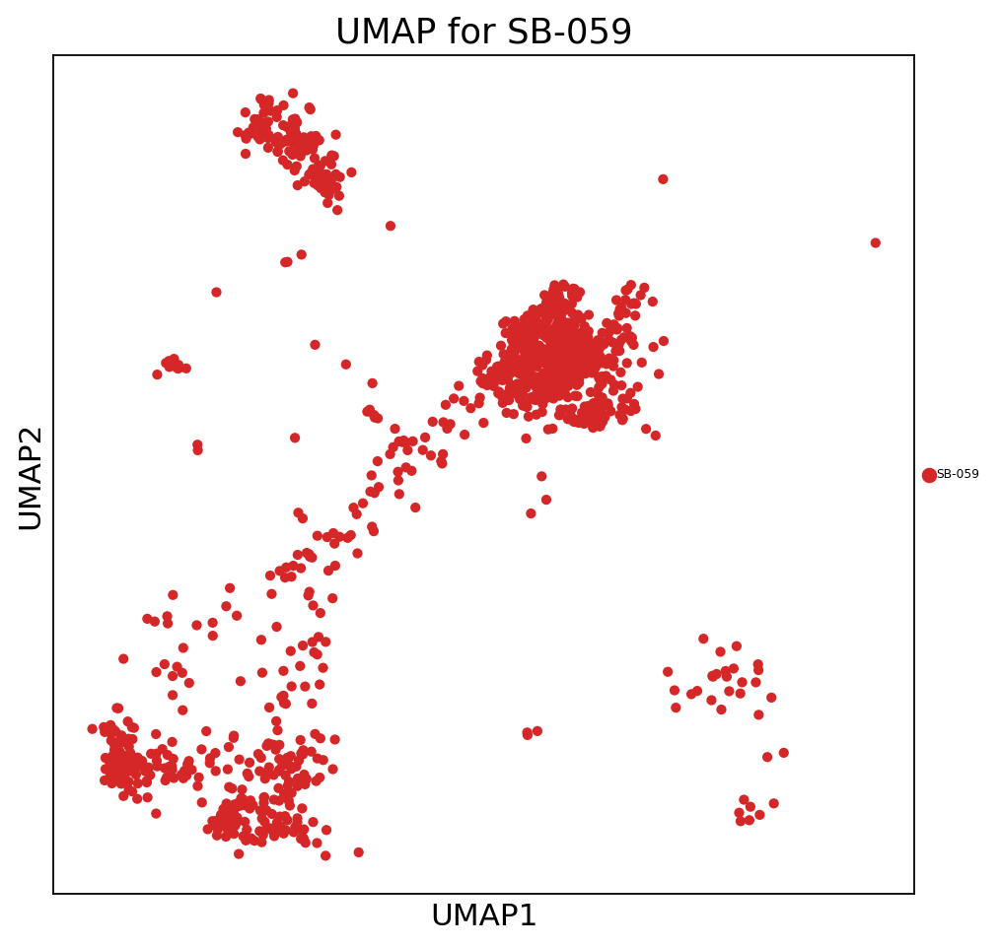

SB-116


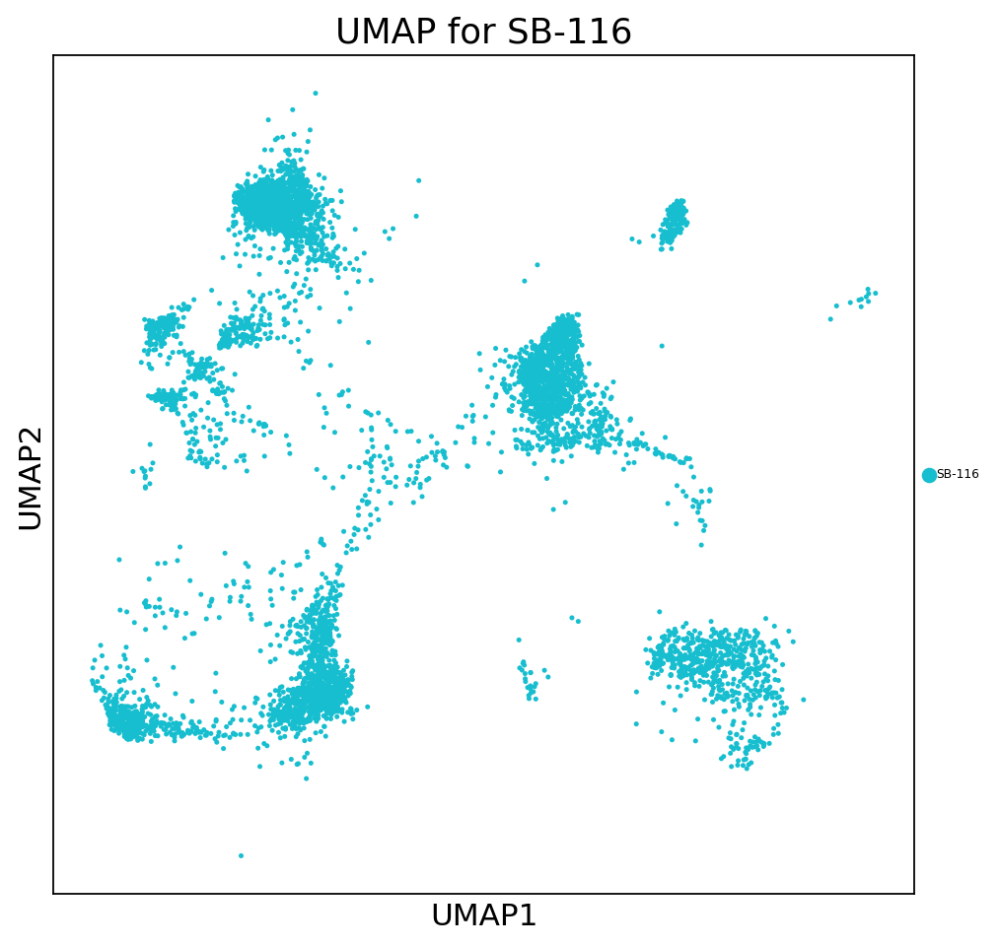

TRA-021


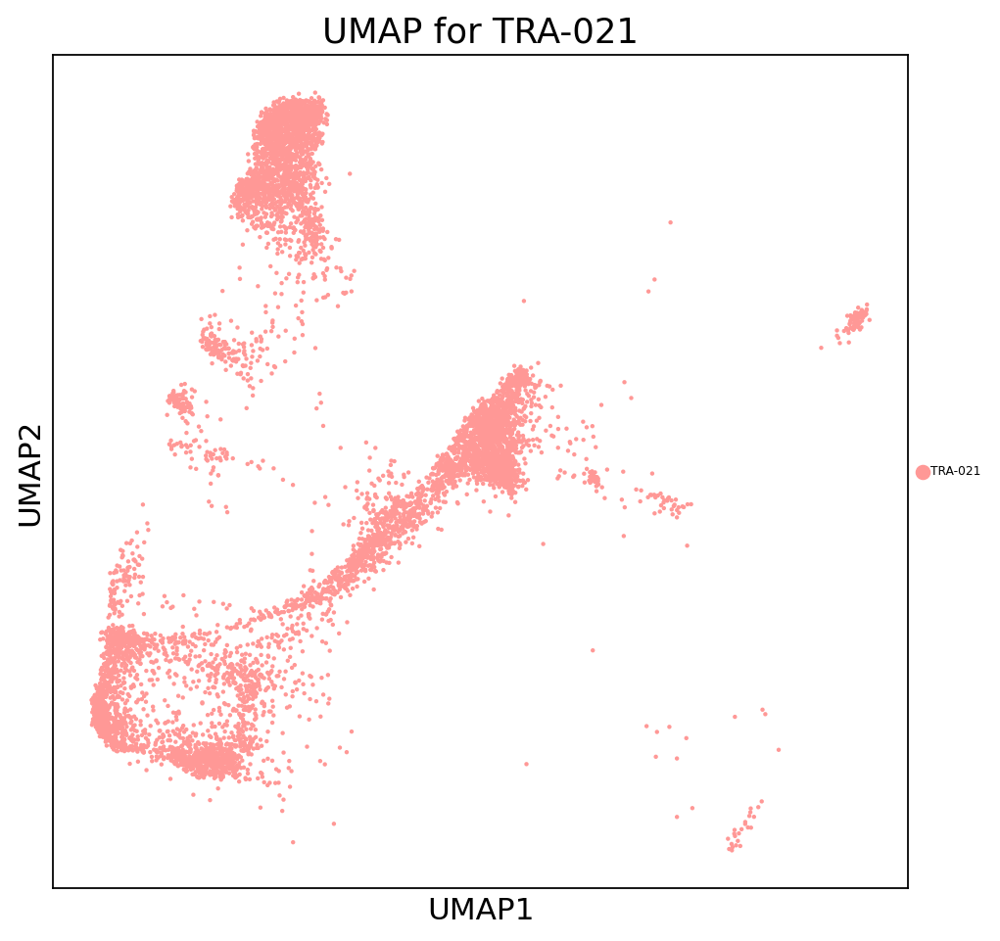

SB-152-1


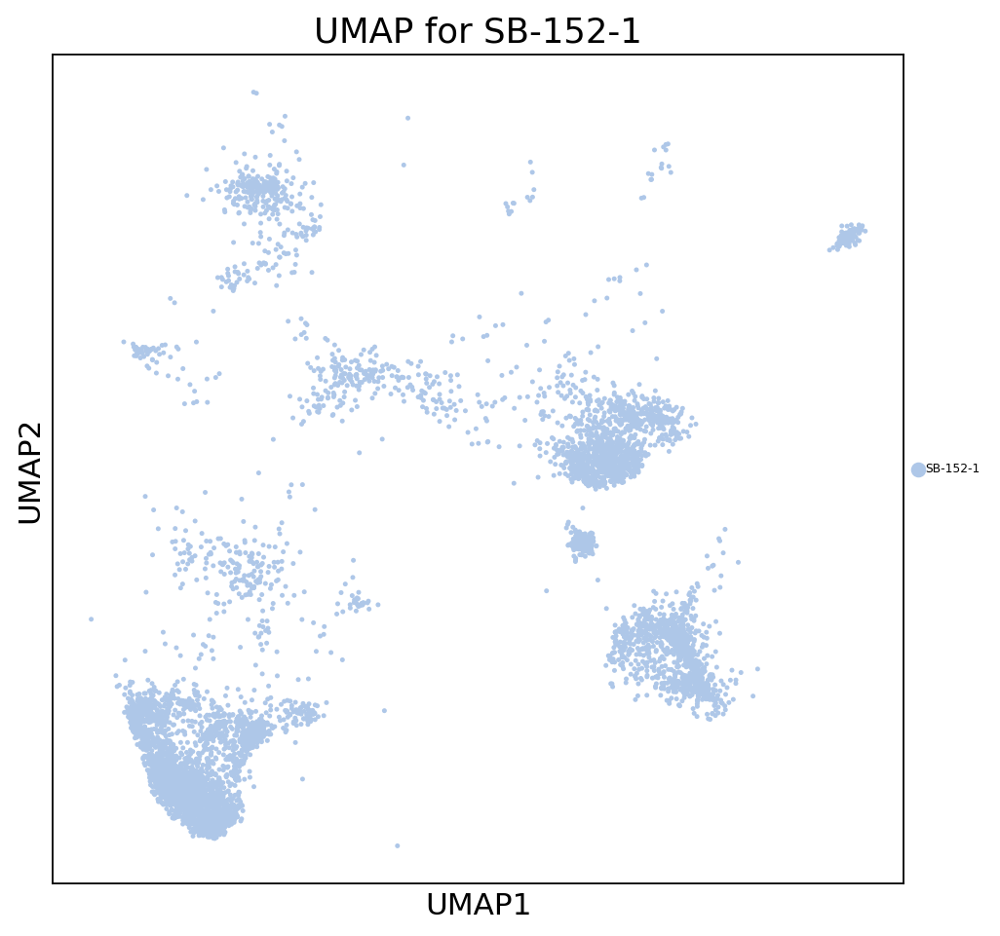

SB-102


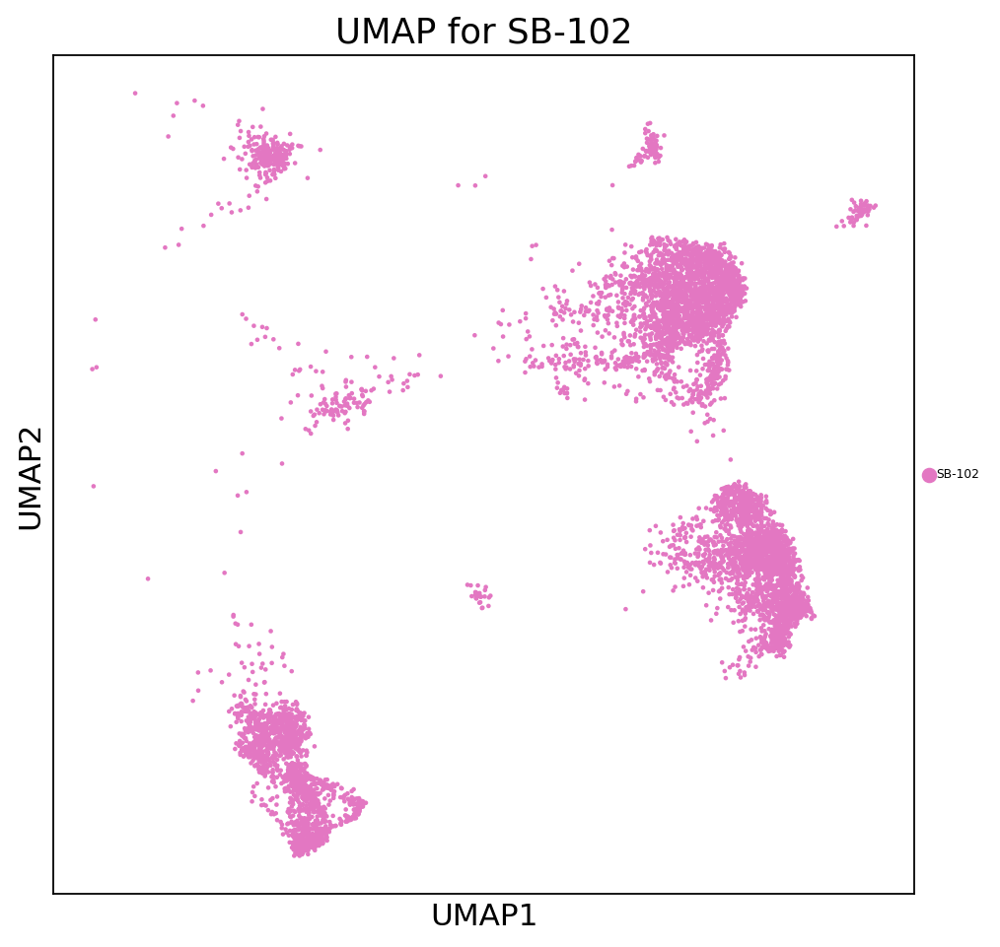

961a


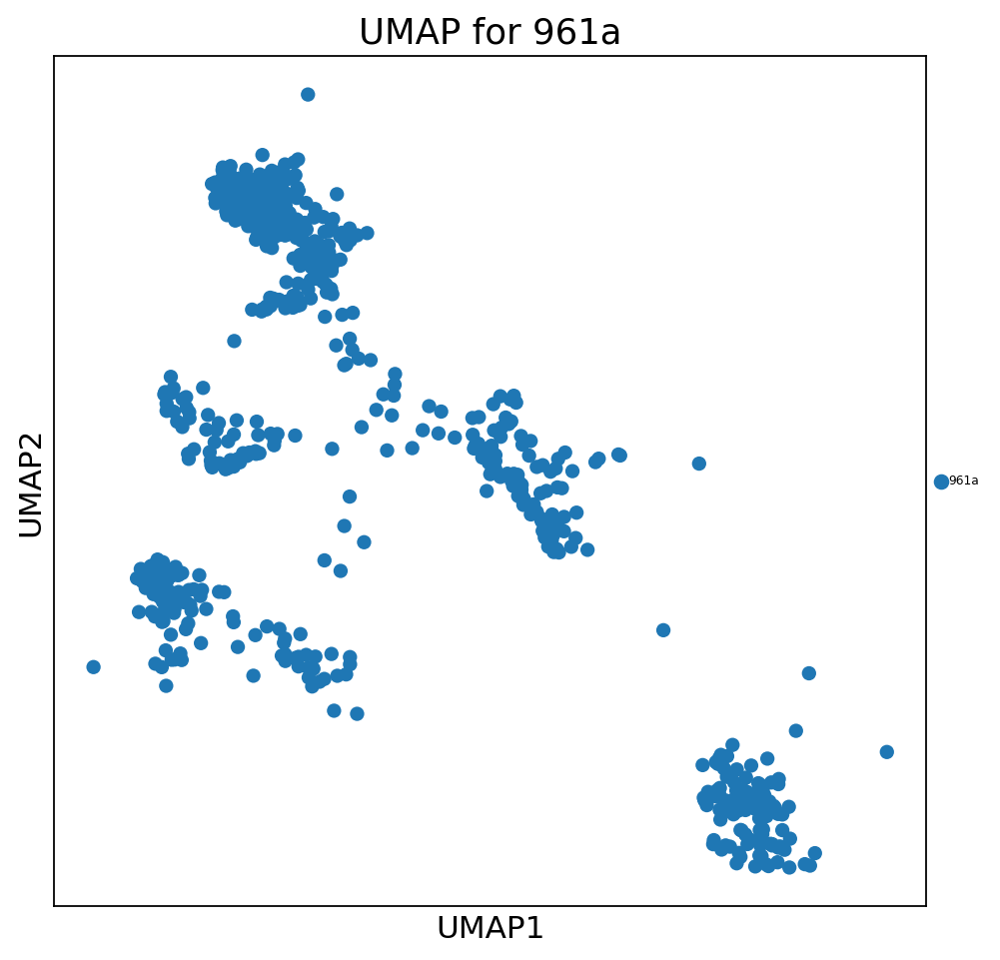

966a


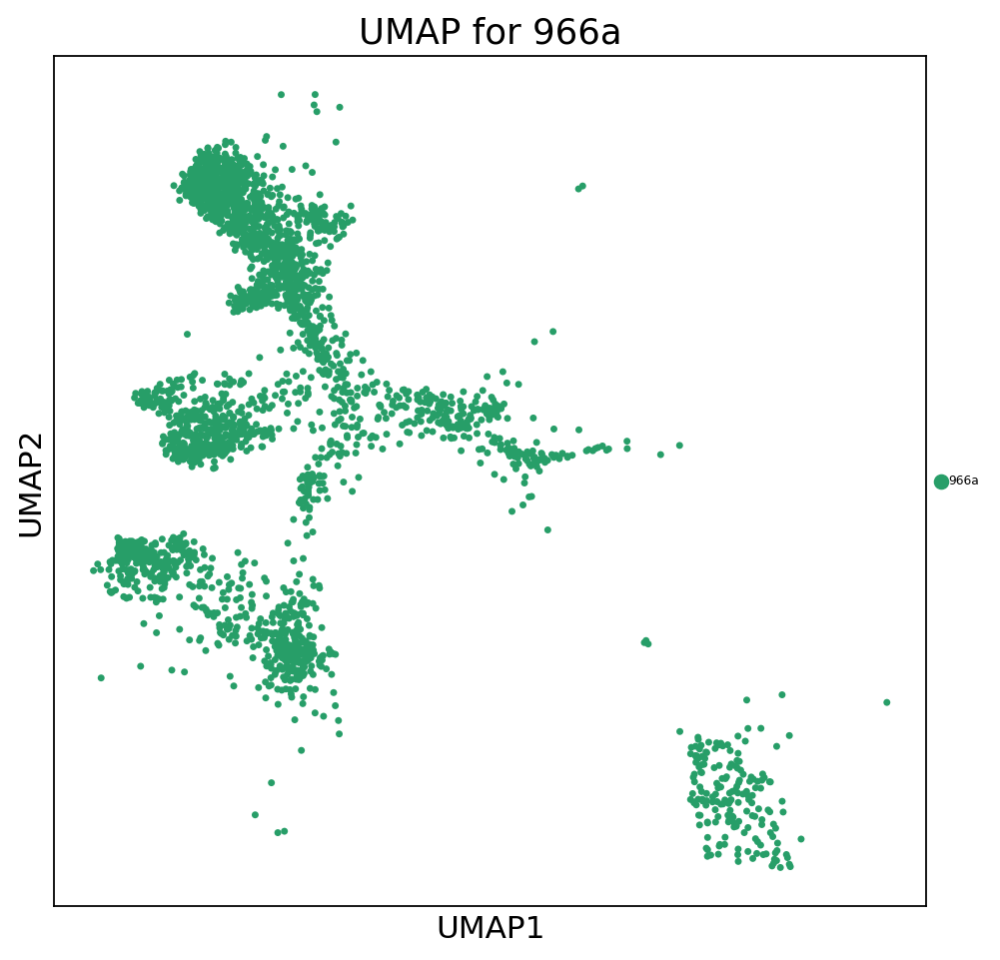

961c


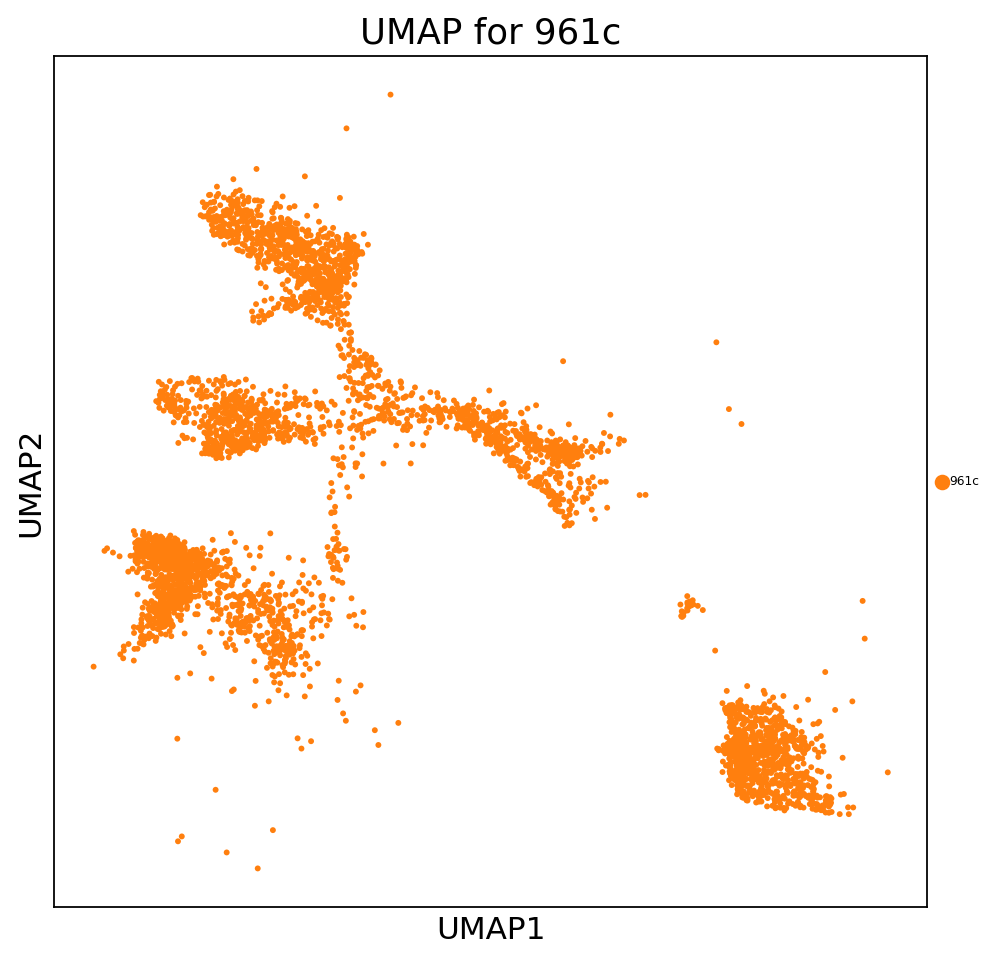

TRA-010


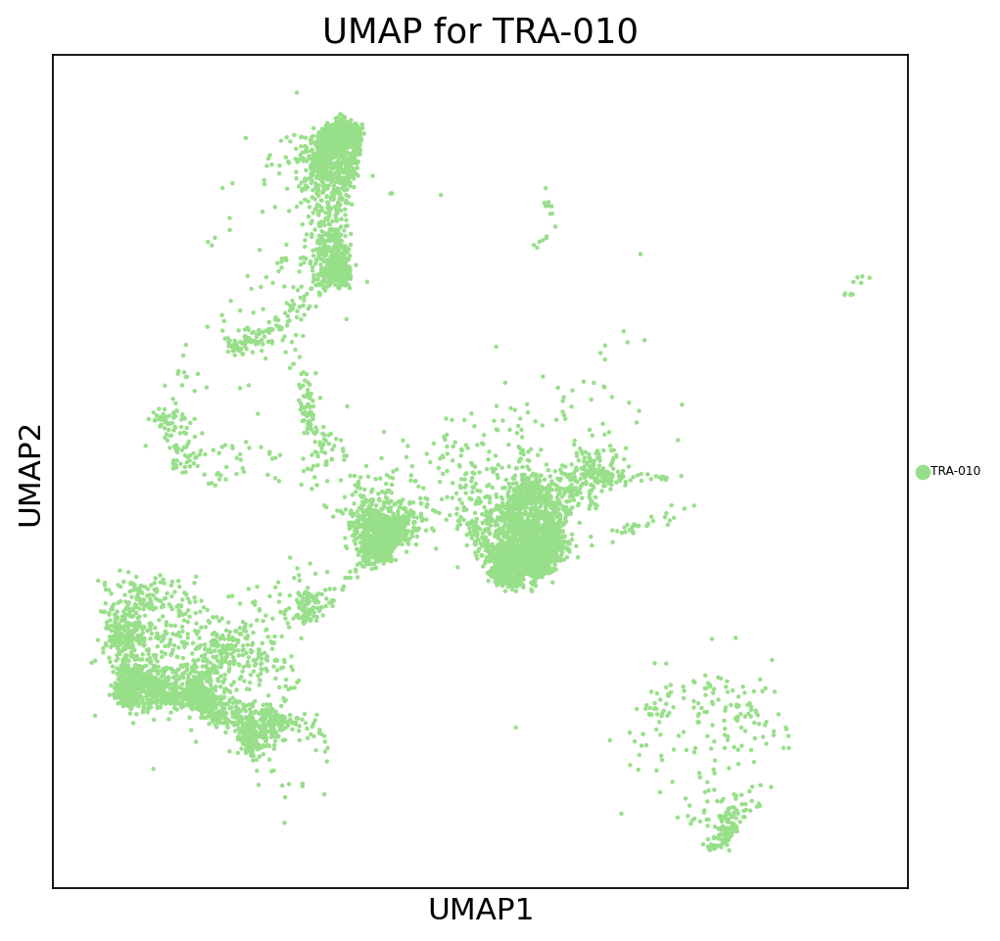

TRA-008


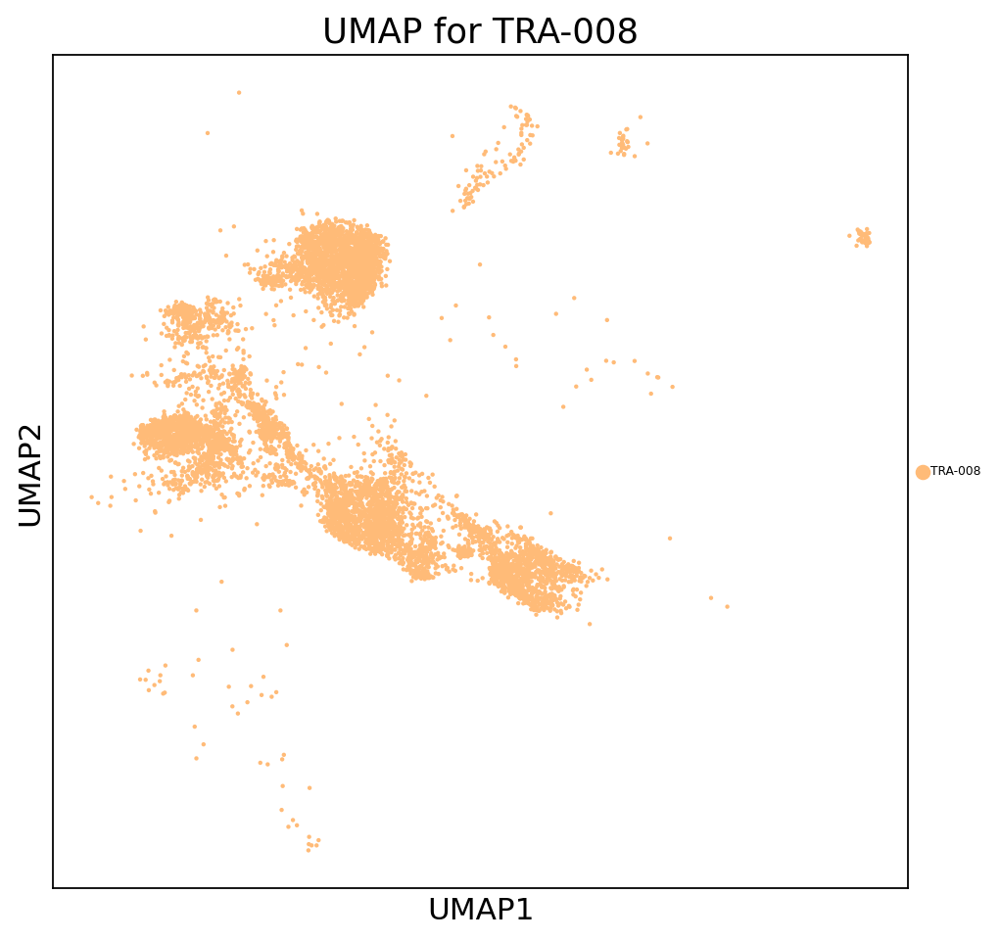

SB-107


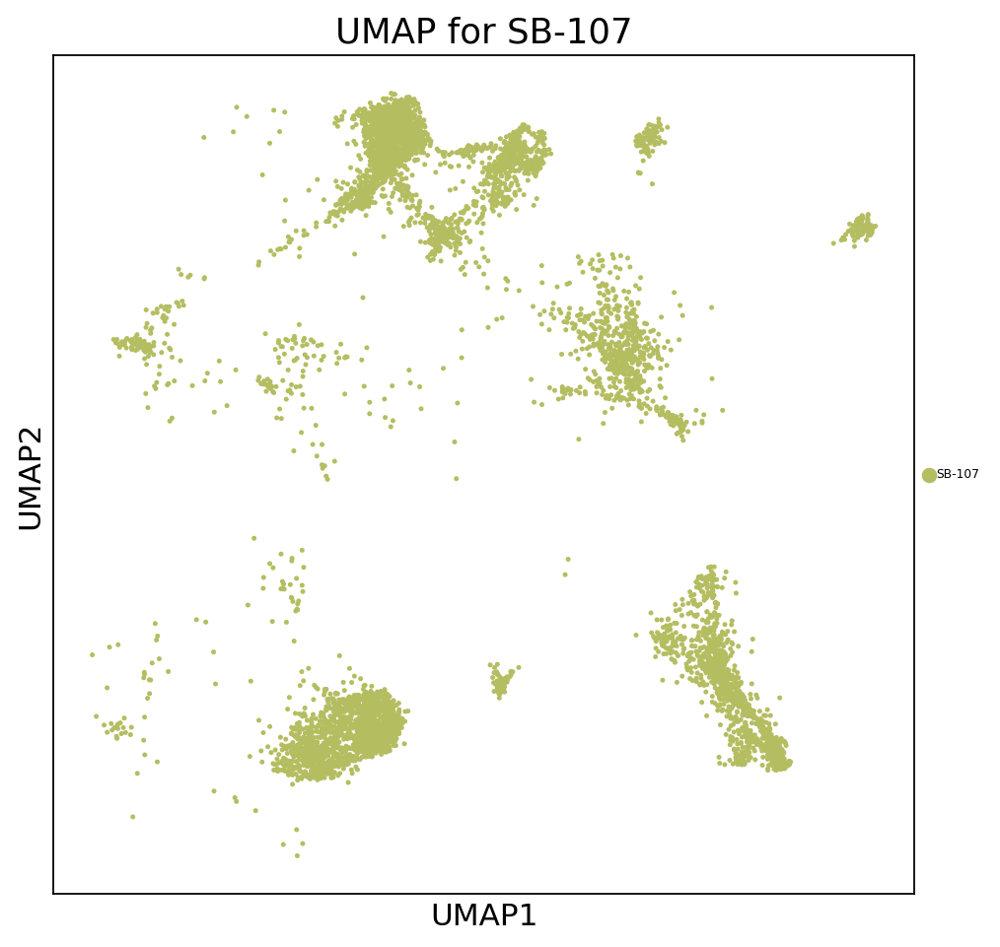

SB-095


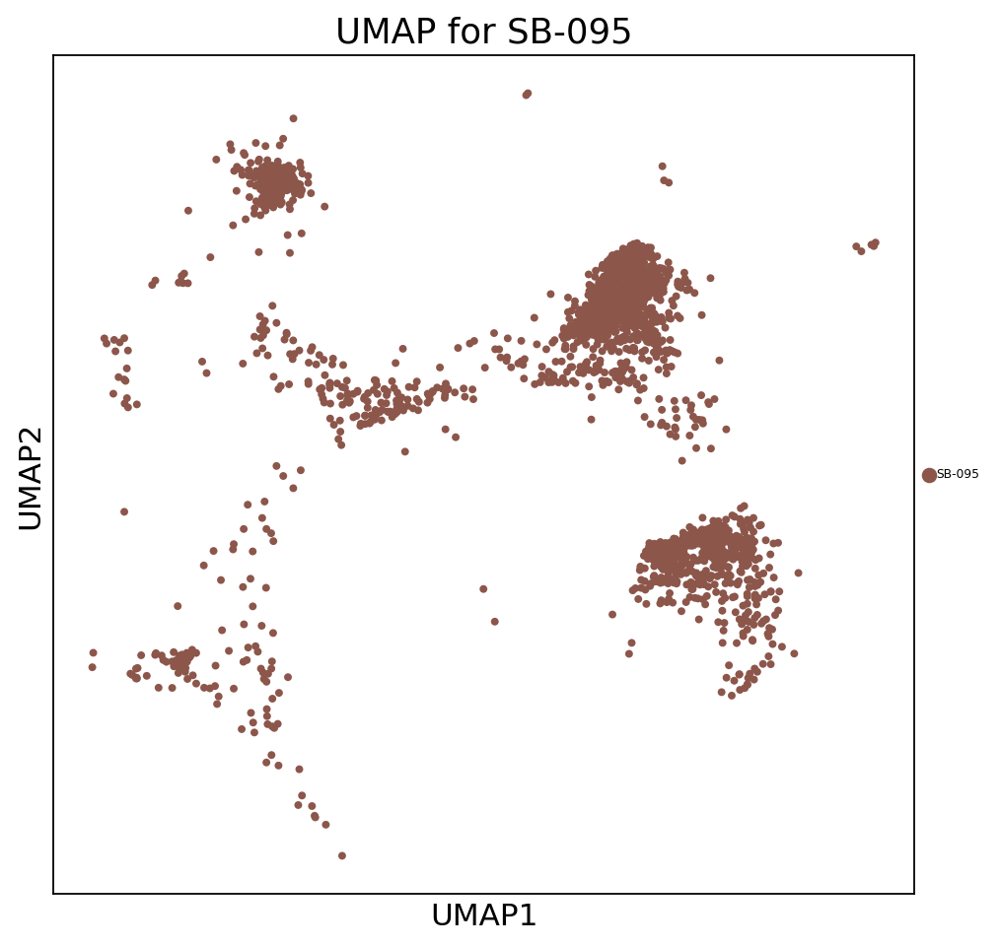

In [65]:
# Loop over each unique batch and generate a UMAP plot
for batch in adata3.obs['sample'].unique():
    print(batch)
    # Create a new adata object for the specific batch
    adata_batch = adata3[adata3.obs['sample'] == batch]
    
    # Plot UMAP for this batch
    sc.pl.umap(adata_batch, color='sample', title=f"UMAP for {batch}")

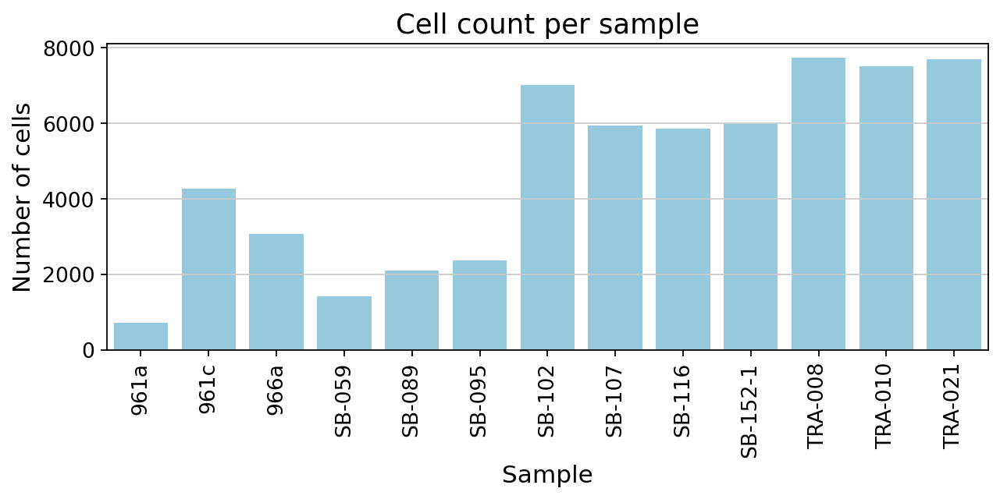

In [66]:
#Check and removal samples with less than 200 cells
import matplotlib.pyplot as plt
import seaborn as sns

# Count number of cells per sample
cell_counts = adata3.obs['sample'].value_counts().sort_index()

# Plot
plt.figure(figsize=(8,4))
sns.barplot(x=cell_counts.index, y=cell_counts.values, color="skyblue")
plt.xticks(rotation=90)
plt.ylabel("Number of cells")
plt.xlabel("Sample")
plt.title("Cell count per sample")
plt.tight_layout()
plt.show()


In [67]:
# Define minimum cell count threshold
#min_cells = 500

# Identify samples that meet the threshold
#valid_samples = cell_counts[cell_counts >= min_cells].index

# Filter the AnnData object
#adata3 = adata3[adata3.obs['sample'].isin(valid_samples)].copy()

#print(f"Kept {len(valid_samples)} samples with ≥ {min_cells} cells.")
#print(f"Remaining cells: {adata3.n_obs}")


# Annotation based on Celina analyses. 

In [68]:
# --- 1) Load metadata file ---
meta = pd.read_csv("Celina_all_meta.tsv", sep="\t")

# --- 2) Select only columns of interest ---
# REQUIRED: first column must be cell IDs
cols_to_keep = ["orig.ident", "sample_name", "disease", "sex","age", "disease_years", "localisation", "pathotype","krenn_score", "fibrosis", "therapy", "autoantibodies","seurat_clusters", "cell_type_merged", "cell_state", "cell_state_short"]   
meta = meta[cols_to_keep]

def fix_cell_id(meta_index, sample):
    barcode = meta_index.split("_")[0]             # AAGTCGTGTGACCGAA-1
    return f"{sample}_{barcode}-GSE00000"          # SB-059_AAGTCGTGTGACCGAA-1-GSE00000

# Create new index with corrected names
meta["fixed_id"] = [
    fix_cell_id(idx, sample)
    for idx, sample in zip(meta.index, meta["orig.ident"])
]
print(meta)
# Set fixed index as the index
meta = meta.set_index("fixed_id")

meta = meta.drop(columns=["orig.ident"])

# --- 4) Keep only metadata rows that exist in the AnnData object ---
meta = meta.loc[meta.index.intersection(adata3.obs_names)]

print(f"Metadata rows kept: {meta.shape[0]} / {adata3.n_obs}")

print(meta)

                      orig.ident sample_name disease sex  age  disease_years  \
AAGTCGTGTGACCGAA-1_1      SB-059       SSc-1     SSc   f   58            5.0   
ATCATTCGTAGAAACT-1_1      SB-059       SSc-1     SSc   f   58            5.0   
CACAGATGTAGTGATA-1_1      SB-059       SSc-1     SSc   f   58            5.0   
CAGTGCGTCGGTCTGG-1_1      SB-059       SSc-1     SSc   f   58            5.0   
CGATGGCCACAGTGAG-1_1      SB-059       SSc-1     SSc   f   58            5.0   
...                          ...         ...     ...  ..  ...            ...   
TTCCTTCAGTAGCAAT-1_18    TRA-021       Tra-6  Trauma   m   25            NaN   
TTGTGGAAGGGACTGT-1_18    TRA-021       Tra-6  Trauma   m   25            NaN   
TTGTTCAGTGAGTAGC-1_18    TRA-021       Tra-6  Trauma   m   25            NaN   
TTTACTGCAATTTCGG-1_18    TRA-021       Tra-6  Trauma   m   25            NaN   
TTTCAGTGTATCCCAA-1_18    TRA-021       Tra-6  Trauma   m   25            NaN   

                      localisation     

In [69]:
# --- 5) Merge into adata.obs ---
adata3.obs = adata3.obs.join(meta, how="left")

print("✅ Metadata merged into adata.obs")

✅ Metadata merged into adata.obs


In [72]:
# --- 6) Remove cells without cell_state annotation ---
adata4 = adata3[~adata3.obs["cell_state"].isna()].copy()
print(f"Remaining cells after filtering: {adata4.n_obs}")
adata4.obs["disease"].unique()

Remaining cells after filtering: 33511


array(['SSc', 'Trauma'], dtype=object)

In [73]:
import scanpy as sc

print("🔄 Recomputing PCA, neighbors, and UMAP...")

# Highly variable genes (again recommended after filtering)
#sc.pp.highly_variable_genes(adata4, n_top_genes=1000)
#adata4 = adata4[:, adata4.var["highly_variable"]].copy()

# PCA
sc.tl.pca(adata4, svd_solver="arpack", use_highly_variable=True)

# Neighbors
sc.pp.neighbors(adata4, n_neighbors=15, n_pcs=50)

# UMAP
sc.tl.umap(adata4)

print("✅ UMAP recomputed on filtered dataset.")


🔄 Recomputing PCA, neighbors, and UMAP...


/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


✅ UMAP recomputed on filtered dataset.


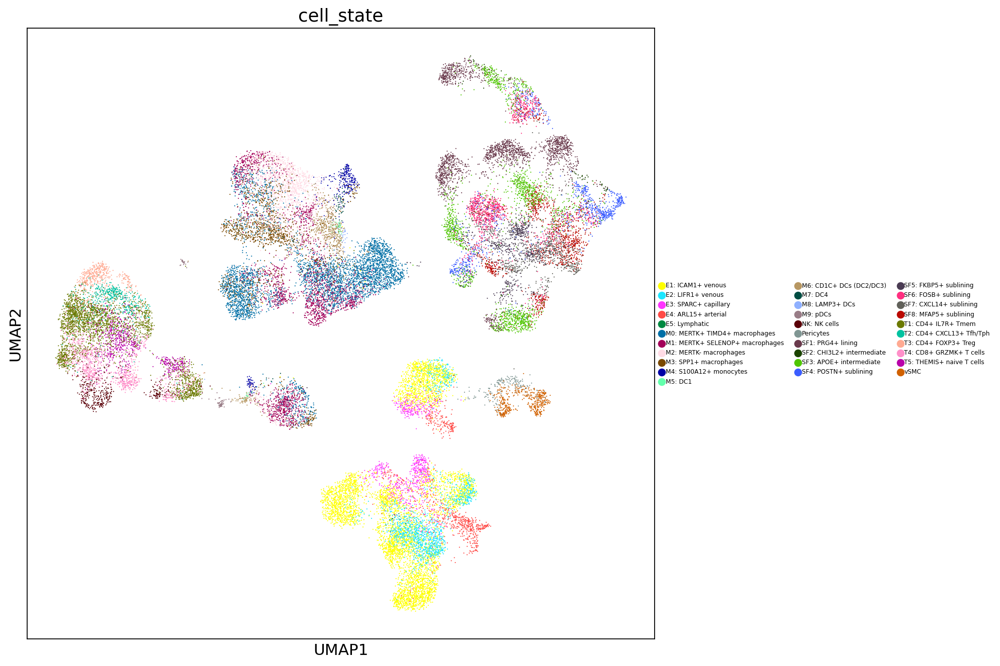

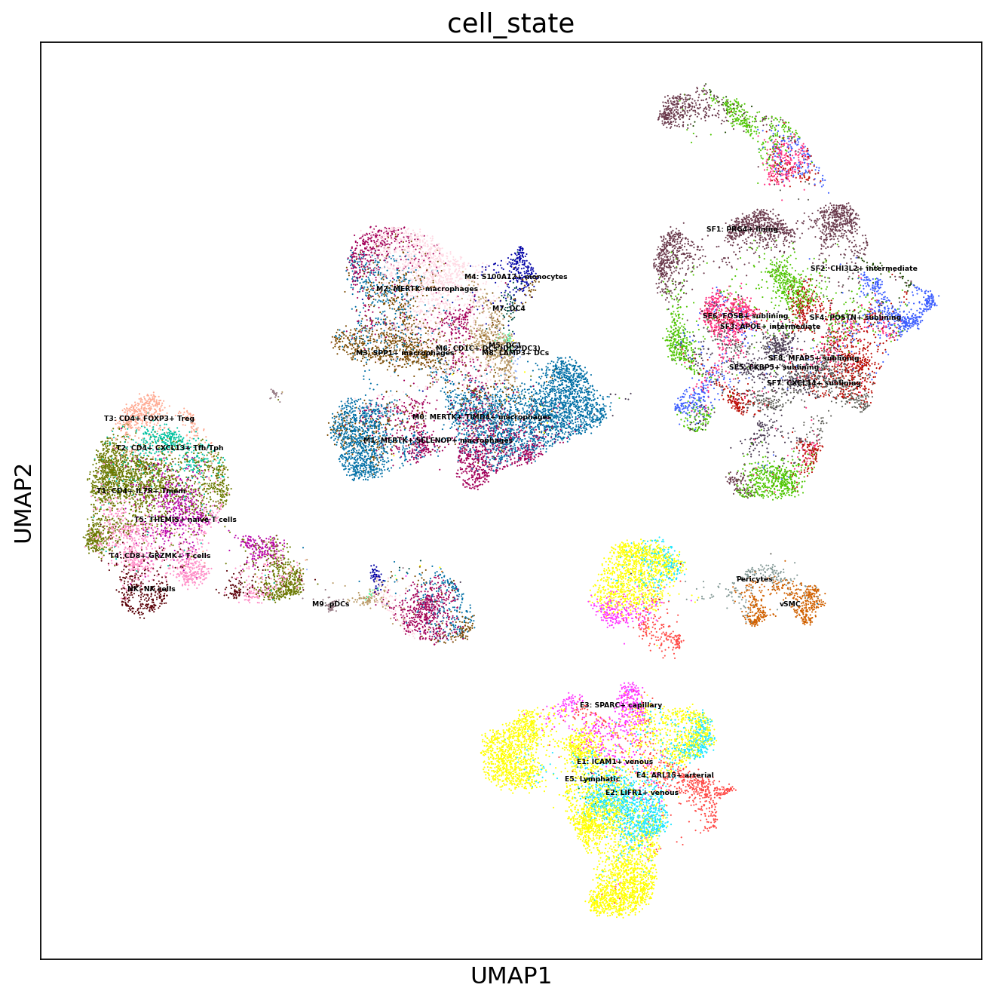

In [74]:
plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata4, color=['cell_state'])

sc.pl.umap(adata4, color=['cell_state'], legend_loc = "on data", legend_fontsize= 'x-small')

In [75]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 500        # minimum cells to keep per cell type
groupby = "cell_state"  # column defining populations

# Prepare empty index list
subsampled_idx = []

# Loop through each cell type and subsample
for cell_type, indices in adata4.obs.groupby(groupby).groups.items():
    n_cells = len(indices)
    if n_cells <= min_keep:
        chosen = indices  # keep all
    else:
        chosen = np.random.choice(indices, size=min_keep, replace=False)
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Create subsampled AnnData
adata_sub = adata4[subsampled_idx, :].copy()

print(f"\nTotal cells before: {adata4.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")


E1: ICAM1+ venous    → kept 500 / 5284 cells
E2: LIFR1+ venous    → kept 500 / 1627 cells
E3: SPARC+ capillary → kept 500 / 779 cells
E4: ARL15+ arterial  → kept 500 / 812 cells
E5: Lymphatic        → kept 15 / 15 cells
M0: MERTK+ TIMD4+ macrophages → kept 500 / 3964 cells
M1: MERTK+ SELENOP+ macrophages → kept 500 / 2227 cells
M2: MERTK- macrophages → kept 500 / 1582 cells
M3: SPP1+ macrophages → kept 500 / 1392 cells
M4: S100A12+ monocytes → kept 303 / 303 cells
M5: DC1              → kept 40 / 40 cells
M6: CD1C+ DCs (DC2/DC3) → kept 500 / 573 cells
M7: DC4              → kept 54 / 54 cells
M8: LAMP3+ DCs       → kept 28 / 28 cells
M9: pDCs             → kept 87 / 87 cells
NK: NK cells         → kept 464 / 464 cells
Pericytes            → kept 183 / 183 cells
SF1: PRG4+ lining    → kept 500 / 1983 cells
SF2: CHI3L2+ intermediate → kept 71 / 71 cells
SF3: APOE+ intermediate → kept 500 / 1781 cells
SF4: POSTN+ sublining → kept 500 / 948 cells
SF5: FKBP5+ sublining → kept 500 / 840 cell

/tmp/ipykernel_3979348/290528760.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for cell_type, indices in adata4.obs.groupby(groupby).groups.items():


In [76]:
sc.tl.rank_genes_groups(adata_sub, groupby='cell_state', method='logreg')
sc.pl.rank_genes_groups(adata_sub)

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [77]:
marker_genes_dict = {'SF1': ['PRG4'],
                     'SF2': 'CHI3L2',
                     'SF3': ['APOE'],
                     'SF4': ['POSTN'],
                     'SF5': ['FKBP5'],
                     'SF6': ['FOSB'],
                     'SF7': ['CXCL14'],
                     'SF8': ['MFAP5']}

categories: E1: ICAM1+ venous, E2: LIFR1+ venous, E3: SPARC+ capillary, etc.
var_group_labels: SF1, SF2, SF3, etc.


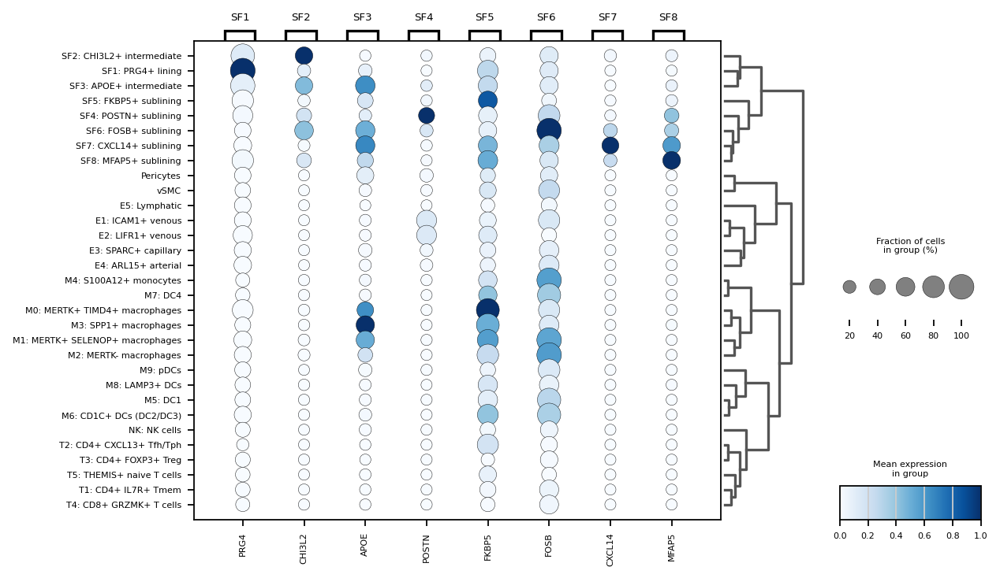

In [78]:
ax = sc.pl.dotplot(adata4, marker_genes_dict, groupby='cell_state', dendrogram=True,
                   standard_scale='var', smallest_dot=40, color_map='Blues', figsize=(8,5))

In [79]:
sc.tl.leiden(
    adata4,
    resolution=2,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,
    key_added="leiden_r2" 
) #Using igraph as flavor there is currently a bug on windows system that block freeze R.

['0', '1', '3', '4', '7', ..., '31', '32', '33', '34', '35']
Length: 36
Categories (36, object): ['0', '1', '2', '3', ..., '32', '33', '34', '35']


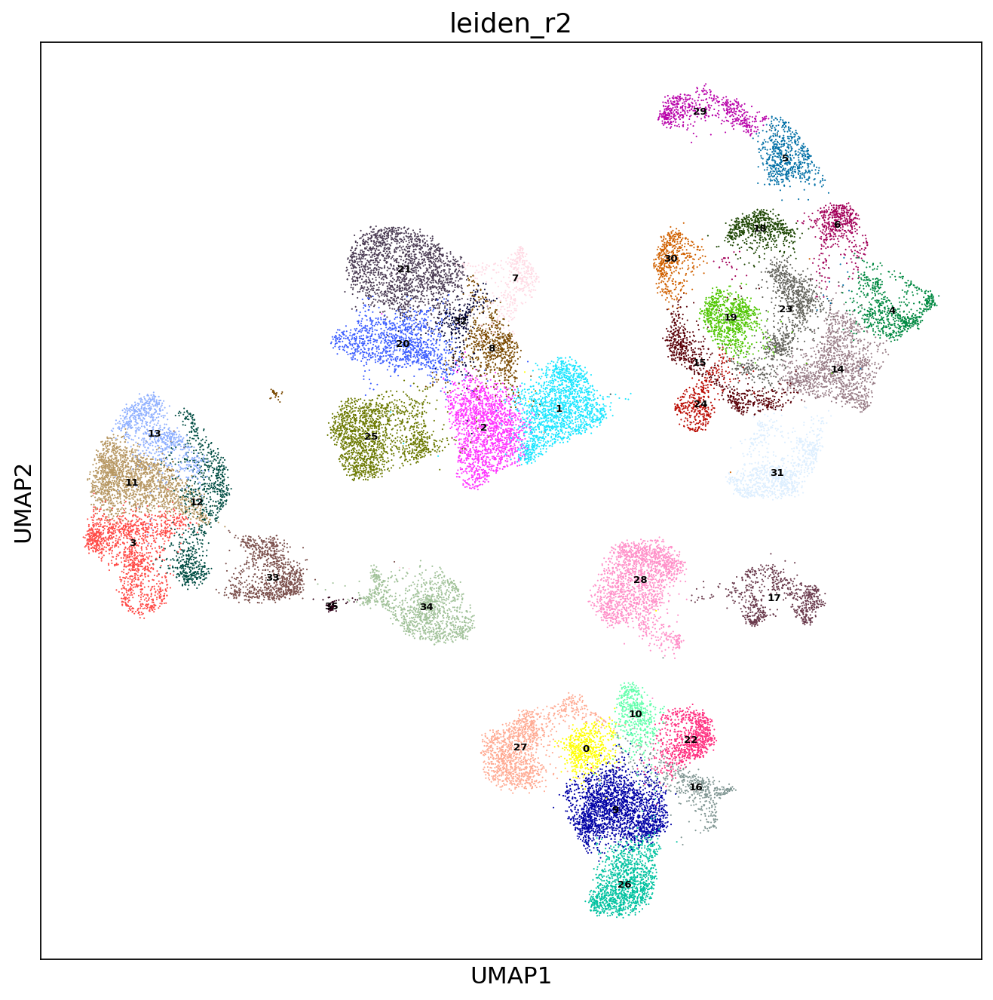

In [80]:
print(adata4.obs['leiden_r2'].unique())
sc.pl.umap(adata4, color='leiden_r2', legend_loc='on data')

In [81]:
sc.tl.leiden(
    adata4,
    resolution=0.4,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,
    key_added="leiden_r0.4" 
) #Using igraph as flavor there is currently a bug on windows system that block freeze R.

['0', '1', '2', '3', '5', ..., '7', '13', '14', '15', '16']
Length: 17
Categories (17, object): ['0', '1', '2', '3', ..., '13', '14', '15', '16']


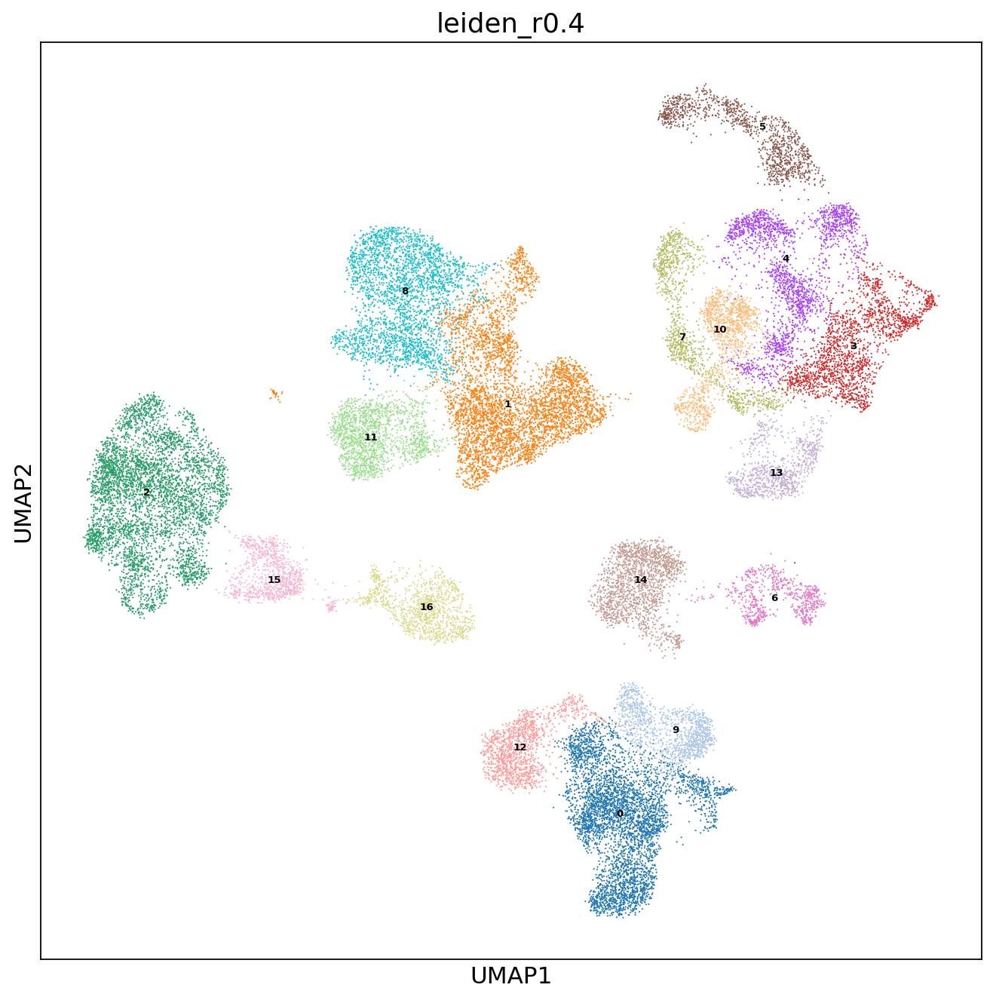

In [82]:
print(adata4.obs['leiden_r0.4'].unique())
sc.pl.umap(adata4, color='leiden_r0.4', legend_loc='on data')

In [83]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 500        # minimum cells to keep per cell type
groupby = "leiden_r0.4"  # column defining populations

# Prepare empty index list
subsampled_idx = []

# Loop through each cell type and subsample
for cell_type, indices in adata4.obs.groupby(groupby).groups.items():
    n_cells = len(indices)
    if n_cells <= min_keep:
        chosen = indices  # keep all
    else:
        chosen = np.random.choice(indices, size=min_keep, replace=False)
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Create subsampled AnnData
adata_sub = adata4[subsampled_idx, :].copy()

print(f"\nTotal cells before: {adata4.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")


0                    → kept 500 / 4367 cells
1                    → kept 500 / 4586 cells
2                    → kept 500 / 4753 cells
3                    → kept 500 / 1930 cells
4                    → kept 500 / 2043 cells
5                    → kept 500 / 1142 cells
6                    → kept 500 / 667 cells
7                    → kept 500 / 1169 cells
8                    → kept 500 / 2925 cells
9                    → kept 500 / 1245 cells
10                   → kept 500 / 1178 cells
11                   → kept 500 / 1558 cells
12                   → kept 500 / 1196 cells
13                   → kept 500 / 909 cells
14                   → kept 500 / 1703 cells
15                   → kept 500 / 988 cells
16                   → kept 500 / 1152 cells

Total cells before: 33511
Total cells after subsampling: 8500


/tmp/ipykernel_3979348/310728643.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for cell_type, indices in adata4.obs.groupby(groupby).groups.items():


/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


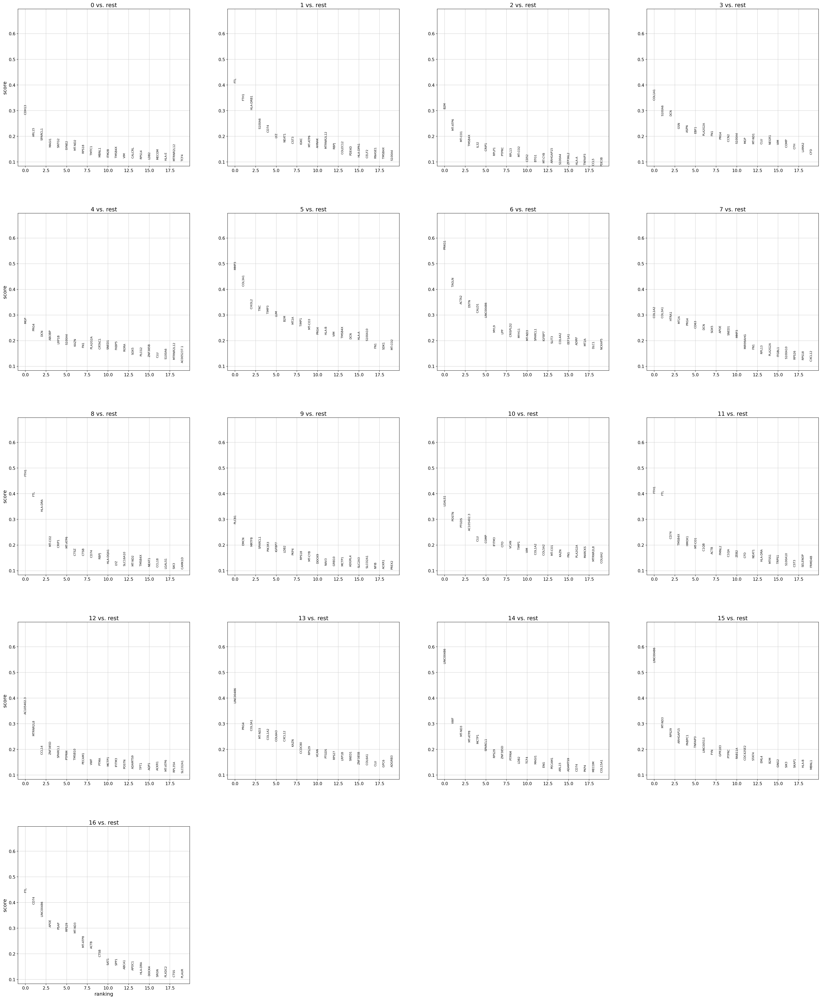

In [84]:
sc.tl.rank_genes_groups(adata_sub, groupby='leiden_r0.4', method='logreg')
sc.pl.rank_genes_groups(adata_sub)

In [85]:
adata4.write("/home/ciperi/data/Atlas_SSC/SYNOVIUM/Unintegrated_synovium_corr_V2_reann.h5ad")

In [86]:
adata4

AnnData object with n_obs × n_vars = 33511 × 21302
    obs: 'n_genes', 'sample', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'orig.ident', 'SampleName', 'DiseaseYears', 'Disease', 'DiseaseName', 'Pathotype', 'Sex', 'Sex2', 'Age', 'Localisation', 'Joint', 'Center', 'BiopsyDate', 'Krenn', 'CD15', 'Vascularisation', 'Lymphoidfollicle', 'Granulomas', 'Fibrosis', 'GCTreatment', 'Therapy', 'DMARDTreatment', 'NOpreviousTreatments', 'Autoantibodies', 'Seropositivity', 'RF', 'anti-CCP', 'HLAB27', 'USB', 'USPD', 'CRP', 'D2T', 'NOJoints', 'INVlargeJoints', 'SystemicManifestations', 'Smoking', 'BMI', 'BMIcat', 'BMIcat2', 'Radiograph', 'AxialInvolvement', 'dataset', 'predicted_doublet', 'doublet_score', 'sample_name', 'disease', 'sex', 'age', 'disease_years', 'localisation', 'pathotype', 'krenn_score', 'fibrosis', 'therapy', 'autoantibodies', 'seurat_clusters', 'cell_type_merged', 'cell_stat